# Seminar 06: Scaling ALS and combining feedback signals


## 1. Short-video feedback

[VK-LSVD](https://huggingface.co/datasets/deepvk/VK-LSVD) records video impressions
with watch time, likes, dislikes, shares and bookmarks. `timespent` and `duration`
are measured in seconds and stored as uint8, so values are capped at 255.
The dataset documentation states that a user–video pair is not shown repeatedly.
We still aggregate duplicate pairs before constructing confidence.

Use **weeks 0–7 for training, week 8 for validation and week 9 for testing**.
These are internal chronological splits within the dataset's official training
period. A positive evaluation target is a future **like, share or bookmark
without a dislike**. A completed view, defined as `watch_ratio >= 0.8`, is a
separate secondary target.

Every model ranks the same training catalog and excludes **all previous
impressions**, including impressions without positive feedback. Report the
coverage lost to new users, new videos and filtering. The evaluation cohort is
sampled from training users before inspecting future labels; training uses every
row in the selected history.

The supplied `up0.001_ip0.001` subset contains active users and popular videos.
Its popularity selection uses a longer period than our internal split. Results
therefore describe this selected audience and catalog, rather than the full feed.


In [9]:
from pathlib import Path
from time import perf_counter
from urllib.request import urlopen
import copy
import importlib.util
import os
import shutil
import subprocess
import sys

# Colab already includes the scientific Python stack. Install missing wheels only.
missing = [spec for name, spec in [("polars", "polars>=1,<2"),
                                  ("implicit", "implicit>=0.7.3,<0.8")]
           if importlib.util.find_spec(name) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "--only-binary=:all:", *missing], check=True)

import polars as pl
import pandas as pd
import matplotlib.pyplot as plt
import implicit
from implicit.cpu.als import AlternatingLeastSquares
from threadpoolctl import threadpool_limits

blas_limit = threadpool_limits(limits=1)  # Avoid nested BLAS/OpenMP oversubscription.
SEED = 42
K = 10
FACTORS = 48
REG = 0.1
ALPHA = 10.0
ITERATIONS = 20
NUM_THREADS = min(8, os.cpu_count() or 2)
TRAIN_WEEKS = list(range(8))
VALID_WEEK, TEST_WEEK = 8, 9
MAX_EVAL_USERS = 3000  # Train on all rows; evaluate a fixed training-user cohort.
SYNTHETIC = os.environ.get("RECSYS_ALS_SYNTHETIC", "0") == "1"
REVISION = "084a18386e149a454dd6dbe0123478e75c6b09ce"
SUBSAMPLE = "up0.001_ip0.001"

if os.environ.get("RECSYS_ALS_SCALING_DATA_DIR"):
    DATA_DIR = Path(os.environ["RECSYS_ALS_SCALING_DATA_DIR"]).expanduser()
elif Path("/content").is_dir():
    DATA_DIR = Path("/content/recsys_als_scaling_data")
else:
    here = Path.cwd()
    if not (here / "seminar.ipynb").exists():
        here = here / "seminars" / "06_als_scaling"
    DATA_DIR = here / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)
print("Data:", DATA_DIR.resolve())
print("Mode:", "SYNTHETIC engineering fixture" if SYNTHETIC else "REAL VK-LSVD")
print("implicit", implicit.__version__, "polars", pl.__version__)


Data: /content/recsys_als_scaling_data
Mode: REAL VK-LSVD
implicit 0.7.3 polars 1.35.2


In [10]:
from collections import defaultdict
import numpy as np
from scipy import sparse
from scipy.sparse.linalg import LinearOperator, cg


In [11]:
def cached_file(relative):
    destination = DATA_DIR / relative
    if destination.exists():
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_suffix(destination.suffix + ".part")
    url = f"https://huggingface.co/datasets/deepvk/VK-LSVD/resolve/{REVISION}/{relative}"
    print("Downloading", relative, flush=True)
    try:
        with urlopen(url, timeout=120) as response, temporary.open("wb") as output:
            shutil.copyfileobj(response, output)
        temporary.replace(destination)
    finally:
        temporary.unlink(missing_ok=True)
    return destination


def synthetic_fixture():
    # Explicit opt-in fixture for engineering checks, never a fallback for real data.
    rng = np.random.default_rng(SEED)
    nu, ni = 180, 360
    users, items = rng.normal(size=(nu, 5)), rng.normal(size=(ni, 5))
    duration = rng.integers(10, 90, ni)
    batches = [[] for _ in range(TEST_WEEK + 1)]
    for u in range(nu):
        order = rng.permutation(ni)
        for w in range(TEST_WEEK + 1):
            for i in order[w * 25:(w + 1) * 25]:
                affinity = 1 / (1 + np.exp(-users[u] @ items[i] / 2))
                dislike = rng.random() < 0.08 * (1 - affinity)
                batches[w].append({
                    "user_id": u * 11 + 100, "item_id": int(i * 7 + 1000),
                    "timespent": float(min(255, duration[i] * affinity * 1.8)),
                    "like": bool(not dislike and rng.random() < 0.25 * affinity),
                    "share": bool(not dislike and rng.random() < 0.07 * affinity),
                    "bookmark": bool(not dislike and rng.random() < 0.08 * affinity),
                    "dislike": bool(dislike), "week": w,
                })
    frames = {w: pl.DataFrame(rows) for w, rows in enumerate(batches)}
    meta = pl.DataFrame({"item_id": np.arange(ni) * 7 + 1000, "duration": duration})
    return frames, meta


columns = ["user_id", "item_id", "timespent", "like", "dislike", "share", "bookmark"]
if SYNTHETIC:
    weeks, item_meta = synthetic_fixture()
else:
    weeks = {}
    for w in range(TEST_WEEK + 1):
        path = cached_file(f"subsamples/{SUBSAMPLE}/train/week_{w:02d}.parquet")
        weeks[w] = pl.read_parquet(path, columns=columns).with_columns(pl.lit(w).alias("week"))
    # Read only needed columns and rows; do not materialize the full metadata table.
    observed_train_items = pl.concat([weeks[w] for w in TRAIN_WEEKS])["item_id"].unique()
    item_meta = (pl.scan_parquet(cached_file("metadata/items_metadata.parquet"))
                 .select("item_id", "duration")
                 .filter(pl.col("item_id").is_in(observed_train_items.implode()))
                 .collect(engine="streaming"))

for w in TRAIN_WEEKS:
    print(f"week {w}: {len(weeks[w]):,} rows")
print("Test downloaded but its labels will be evaluated only after model selection.")


week 0: 625,523 rows
week 1: 953,185 rows
week 2: 1,160,443 rows
week 3: 1,223,310 rows
week 4: 1,437,122 rows
week 5: 963,319 rows
week 6: 1,388,849 rows
week 7: 1,894,300 rows
Test downloaded but its labels will be evaluated only after model selection.


Train shape: (10000, 9420) evaluation cohort: 3000
shape: (1, 4)
┌─────────┬──────────┬──────────┬─────────────┐
│ len     ┆ like     ┆ dislike  ┆ watch_ratio │
│ ---     ┆ ---      ┆ ---      ┆ ---         │
│ u32     ┆ f64      ┆ f64      ┆ f64         │
╞═════════╪══════════╪══════════╪═════════════╡
│ 9646051 ┆ 0.009638 ┆ 0.000419 ┆ 0.459046    │
└─────────┴──────────┴──────────┴─────────────┘


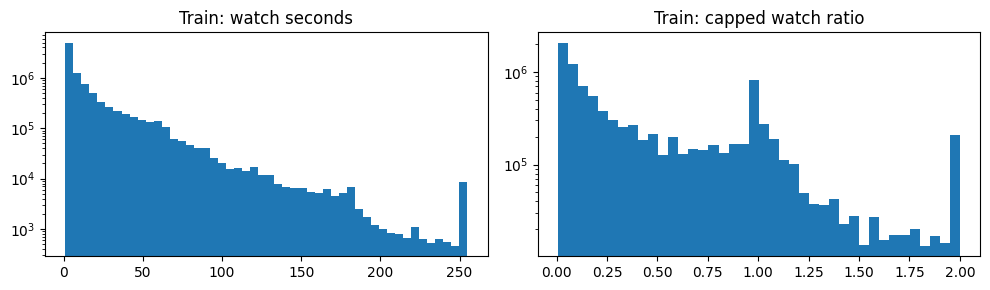

In [12]:
class Registry:
    '''Append-only raw-ID mapping; an existing row never changes its meaning.'''
    def __init__(self):
        self.users, self.items = {}, {}

    def extend(self, frame):
        for name, mapping in [("user_id", self.users), ("item_id", self.items)]:
            for value in sorted(set(frame[name].to_list()) - mapping.keys()):
                mapping[value] = len(mapping)

    @property
    def shape(self):
        return len(self.users), len(self.items)

    def encode(self, frame):
        return frame.with_columns(
            pl.col("user_id").replace_strict(self.users, default=None, return_dtype=pl.Int32).alias("u"),
            pl.col("item_id").replace_strict(self.items, default=None, return_dtype=pl.Int32).alias("i"),
        )


registry = Registry()
shapes = {}
for w in TRAIN_WEEKS:
    registry.extend(weeks[w])
    shapes[w] = registry.shape
train_events = pl.concat([weeks[w] for w in TRAIN_WEEKS])
train_events = train_events.join(item_meta, on="item_id", how="left").with_columns(
    pl.when(pl.col("duration").fill_null(0) > 0)
      .then((pl.col("timespent").cast(pl.Float64) / pl.col("duration")).clip(0, 2))
      .otherwise(0.).alias("watch_ratio")
)
train_events = registry.encode(train_events)
rng = np.random.default_rng(SEED)
eval_cohort = np.sort(rng.choice(registry.shape[0], min(MAX_EVAL_USERS, registry.shape[0]), replace=False))
print("Train shape:", registry.shape, "evaluation cohort:", len(eval_cohort))
print(train_events.select(pl.len(), pl.col("like").mean(), pl.col("dislike").mean(),
                          pl.col("watch_ratio").mean()))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(train_events["timespent"].to_numpy(), bins=50)
axes[0].set(title="Train: watch seconds", yscale="log")
axes[1].hist(train_events["watch_ratio"].to_numpy(), bins=40)
axes[1].set(title="Train: capped watch ratio", yscale="log")
plt.tight_layout()
plt.show()


### Experiment 1. Watch time depends on video length

Twenty seconds means two replays of a ten-second clip but only one sixth of a
two-minute clip. The capped ratio $w=\min(t/d,2)$ assigns these events values
$2$ and $1/6$. Compare seconds, completion ratios and
$P(\mathrm{positive\ action}\mid w\text{ in a bin})$ across video lengths.
These are associations in training data; they do not establish a causal effect
of completion on engagement.


,duration bucket,shows,mean seconds,mean ratio,action rate
0,15–39s,3183586,11.484025,0.456504,0.011414
1,40–89s,3744893,22.812162,0.388772,0.013385
2,90s+,813412,30.616861,0.240539,0.009528
3,<15s,1904160,6.833739,0.694843,0.013458


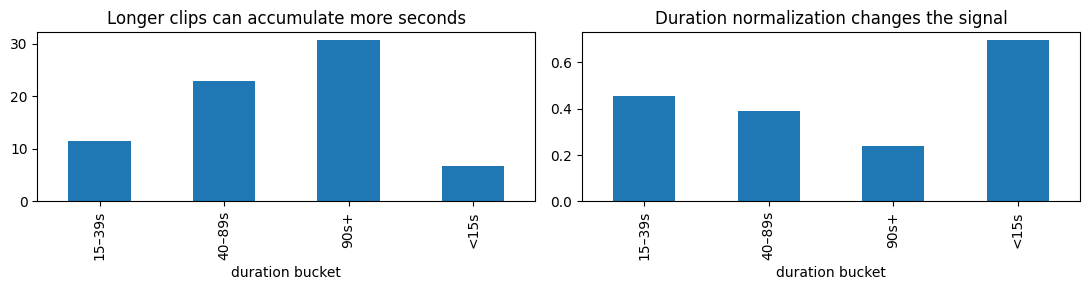

In [13]:
duration_eda = train_events.with_columns(
    pl.when(pl.col("duration") < 15).then(pl.lit("<15s"))
      .when(pl.col("duration") < 40).then(pl.lit("15–39s"))
      .when(pl.col("duration") < 90).then(pl.lit("40–89s"))
      .otherwise(pl.lit("90s+")).alias("duration bucket"),
    (pl.col("like") | pl.col("share") | pl.col("bookmark")).alias("positive action"),
)
duration_table = duration_eda.group_by("duration bucket").agg(
    pl.len().alias("shows"), pl.col("timespent").mean().alias("mean seconds"),
    pl.col("watch_ratio").mean().alias("mean ratio"),
    pl.col("positive action").mean().alias("action rate"),
).sort("duration bucket").pipe(lambda frame: pd.DataFrame(frame.to_dict(as_series=False)))
display(duration_table)
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
duration_table.plot.bar(x="duration bucket", y="mean seconds", ax=axes[0], legend=False)
duration_table.plot.bar(x="duration bucket", y="mean ratio", ax=axes[1], legend=False)
axes[0].set_title("Longer clips can accumulate more seconds")
axes[1].set_title("Duration normalization changes the signal")
plt.tight_layout(); plt.show()


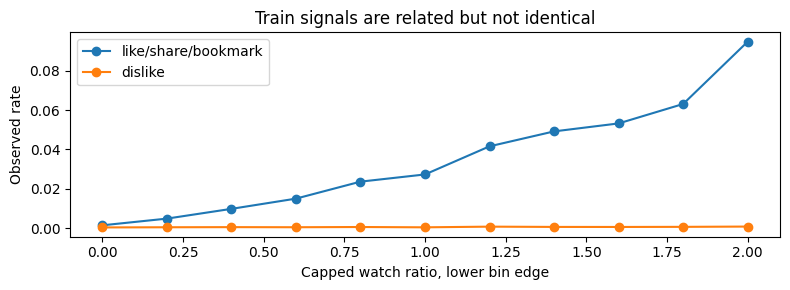

,bin,shows,action rate,dislike rate
0,0,4419465,0.001421,0.000345
1,1,1280218,0.004824,0.000430
2,2,750431,0.009790,0.000494
3,3,590170,0.014989,0.000442
4,4,645854,0.023628,0.000559
5,5,1340475,0.027287,0.000401
6,6,185308,0.041590,0.000745
7,7,99605,0.049184,0.000602
8,8,71963,0.053236,0.000584
9,9,62500,0.063120,0.000640


In [14]:
ratio_table = (duration_eda.with_columns((pl.col("watch_ratio") * 5).floor().cast(pl.Int32).alias("bin"))
               .group_by("bin").agg(pl.len().alias("shows"),
                    pl.col("positive action").mean().alias("action rate"),
                    pl.col("dislike").mean().alias("dislike rate"))
               .sort("bin"))
ratio_table = pd.DataFrame(ratio_table.to_dict(as_series=False))
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(ratio_table["bin"] / 5, ratio_table["action rate"], "o-", label="like/share/bookmark")
ax.plot(ratio_table["bin"] / 5, ratio_table["dislike rate"], "o-", label="dislike")
ax.set(xlabel="Capped watch ratio, lower bin edge", ylabel="Observed rate", title="Train signals are related but not identical")
ax.legend(); plt.tight_layout(); plt.show()
display(ratio_table)


Watch time and deliberate actions capture different aspects of interest.
A missing like is not a dislike, and a completed view can coexist with an
explicit negative reaction. Separate channels preserve these distinctions.

### Experiment 2. Signal overlap and user coverage

$$J(A,B)=\frac{|A\cap B|}{|A\cup B|},\qquad
\operatorname{UserCoverage}_s=\frac{|\{u:\exists i\;s_{ui}>0\}|}{m}.$$

High overlap suggests redundant evidence. Low overlap can indicate a different
intent or simply a rare event. User coverage determines how often a separate
signal model needs a fallback.


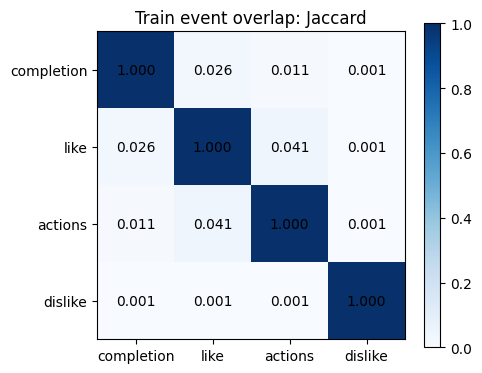

,signal,events,user coverage
0,completion,2605767,0.9999
1,like,92964,0.6266
2,actions,31788,0.5137
3,dislike,4043,0.1307


Completed view + explicit dislike: 1335


In [15]:
signal_flags = {
    "completion": train_events["watch_ratio"].to_numpy() >= .8,
    "like": train_events["like"].to_numpy(),
    "actions": train_events["share"].to_numpy() | train_events["bookmark"].to_numpy(),
    "dislike": train_events["dislike"].to_numpy(),
}
names = list(signal_flags)
jaccard = np.array([[np.sum(signal_flags[a] & signal_flags[b]) /
                     max(np.sum(signal_flags[a] | signal_flags[b]), 1)
                     for b in names] for a in names])
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(jaccard, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(len(names)), names); ax.set_yticks(range(len(names)), names)
for row in range(len(names)):
    for col in range(len(names)):
        ax.text(col, row, f"{jaccard[row, col]:.3f}", ha="center", va="center")
fig.colorbar(im, ax=ax); ax.set_title("Train event overlap: Jaccard")
plt.tight_layout(); plt.show()
display(pd.DataFrame([
    {"signal": s, "events": int(mask.sum()),
     "user coverage": np.unique(train_events["u"].to_numpy()[mask]).size / registry.shape[0]}
    for s, mask in signal_flags.items()]))
print("Completed view + explicit dislike:", int((signal_flags["completion"] & signal_flags["dislike"]).sum()))


### Experiment 3. The feedback stream changes over time

Let $\rho_t=|\Omega_t|/(m_tn_t)$ denote weekly density and
$q_t=|\mathrm{actions}_t|/|\Omega_t|$ the action rate. Changes in traffic,
catalog size and audience composition can change ranking metrics even when
the algorithm is unchanged. Inspect the training weeks before comparing models.


,week,shows,users,items,like rate,mean ratio
0,0,625523,9861,4026,0.010826,0.473425
1,1,953185,9911,4637,0.009454,0.453740
2,2,1160443,9937,5171,0.009518,0.444859
3,3,1223310,9956,5645,0.009372,0.430230
4,4,1437122,9978,6292,0.010028,0.463088
5,5,963319,9975,6547,0.011030,0.440020
6,6,1388849,9977,7276,0.009413,0.467231
7,7,1894300,9992,8186,0.008743,0.484875


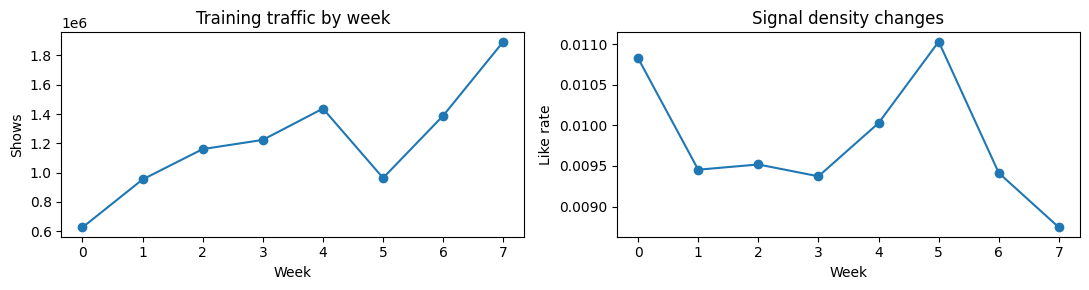

In [16]:
weekly_signal_table = train_events.group_by("week").agg(
    pl.len().alias("shows"), pl.col("user_id").n_unique().alias("users"),
    pl.col("item_id").n_unique().alias("items"), pl.col("like").mean().alias("like rate"),
    pl.col("watch_ratio").mean().alias("mean ratio"),
).sort("week").pipe(lambda frame: pd.DataFrame(frame.to_dict(as_series=False)))
display(weekly_signal_table)
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(weekly_signal_table.week, weekly_signal_table.shows, "o-")
axes[0].set(title="Training traffic by week", xlabel="Week", ylabel="Shows")
axes[1].plot(weekly_signal_table.week, weekly_signal_table["like rate"], "o-")
axes[1].set(title="Signal density changes", xlabel="Week", ylabel="Like rate")
plt.tight_layout(); plt.show()


## 2. From explicit ALS to confidence-weighted iALS

Let $X\in\mathbb R^{m\times d}$ contain user factors and
$Y\in\mathbb R^{n\times d}$ contain video factors, with score
$\hat p_{ui}=x_u^\top y_i$. Explicit ALS fits ratings observed on $\Omega$.
Implicit ALS instead separates **preference** $p_{ui}$ from **confidence**
$c_{ui}$ and includes **every** user–item pair:

$$L(X,Y)=\sum_{u=1}^m\sum_{i=1}^n c_{ui}(p_{ui}-x_u^\top y_i)^2
 +\lambda(\|X\|_F^2+\|Y\|_F^2).$$

The usual positive-feedback construction is $p_{ui}=\mathbf1[r_{ui}>0]$,
$c_{ui}=1+\alpha r_{ui}$. Unobserved pairs have $p=0,c=1$: zero is a weak
modeling target, not an observed rejection. An explicit dislike can have
**$p=0,c\gg1$**, penalizing a positive score strongly without treating the
event as a rating of $-1$. A skip, a missing like and a dislike remain distinct.

Fix $Y$ and differentiate with respect to one user vector:

$$\frac12\nabla_{x_u}L=(Y^\top C_uY+\lambda I)x_u-Y^\top C_up_u=0,$$
$$A_ux_u=b_u,\qquad A_u=Y^\top C_uY+\lambda I,\quad b_u=Y^\top C_up_u.$$

For $\lambda>0$ and $c_{ui}>0$, $A_u$ is positive definite. Solve the linear
system rather than computing its inverse. The item update follows by symmetry.

### Reuse the Gram matrix

Let $I_u$ contain stored observations, including explicit negatives. Every
other pair has $c=1,p=0$, so:

$$G_Y=Y^\top Y,\qquad
A_u=G_Y+\sum_{i\in I_u}(c_{ui}-1)y_iy_i^\top+\lambda I,$$
$$b_u=\sum_{i\in I_u}c_{ui}p_{ui}y_i.$$

Compute $G_Y$ once per user half-step. After updating all users, compute
$G_X=X^\top X$ for the item half-step. Keep $Y$ fixed across user blocks.

For one positive observation with $c_a=6$ and one dislike with $c_b=11$:

$A_u=G_Y+5y_ay_a^\top+10y_by_b^\top+\lambda I$, while $b_u=6y_a$.
The dislike contributes to $A_u$ but not to $b_u$. An empty row has $b_u=0$,
so its exact minimizing factor is zero.

### Confidence in `implicit`

The CSR matrix stores **complete confidence values**. A stored $+c$ means
$p=1$; a stored $-c$ means $p=0$ with weight $|c|$. An absent entry means
$p=0,c=1$. The library's `alpha` multiplies stored values. We construct
$1+\alpha r$ ourselves and set the library's `alpha=1.0`.

Aggregate positive and negative evidence before assigning preference and
confidence. Adding signed confidence matrices can cancel evidence accidentally.


In [17]:
def signed_confidence(mass, dislike, alpha=10.):
    '''Return implicit's signed C; any explicit dislike overrides a positive mass.'''
    mass = np.asarray(mass, dtype=np.float64)
    if np.any(~np.isfinite(mass)) or np.any(mass < 0) or alpha < 0:
        raise ValueError("Positive finite signal mass and nonnegative alpha required")
    result = np.where(mass > 0, 1. + alpha * mass, 0.)
    return np.where(dislike, -(1. + alpha), result)


def update_rows(C, Y, reg, batch_size=32):
    '''One exact ALS half-step; C stores signed confidence, absent entries mean c=1.'''
    if reg <= 0 or batch_size < 1:
        raise ValueError("reg and batch_size must be positive")
    C = C.tocsr()
    d = Y.shape[1]
    base = Y.T @ Y + reg * np.eye(d)
    result = np.empty((C.shape[0], d), dtype=np.float64)
    for begin in range(0, C.shape[0], batch_size):
        end = min(begin + batch_size, C.shape[0])
        A = np.broadcast_to(base, (end - begin, d, d)).copy()
        b = np.zeros((end - begin, d))
        for offset, u in enumerate(range(begin, end)):
            start, stop = C.indptr[u:u + 2]
            idx, value = C.indices[start:stop], C.data[start:stop]
            local = Y[idx]
            c = np.abs(value)
            A[offset] += local.T @ ((c - 1)[:, None] * local)
            b[offset] = local.T @ np.where(value > 0, c, 0.)
        result[begin:end] = np.linalg.solve(A, b[..., None])[..., 0]
    return result


def als_loss(C, X, Y, reg):
    '''Exact unnormalized objective in O((m+n)d² + nnz*d), no dense m×n matrix.'''
    coo = C.tocoo()
    all_pairs_zero_loss = np.sum((X.T @ X) * (Y.T @ Y))
    correction = 0.
    for start in range(0, coo.nnz, 65536):
        part = slice(start, start + 65536)
        scores = np.einsum("ij,ij->i", X[coo.row[part]], Y[coo.col[part]])
        c, p = np.abs(coo.data[part]), (coo.data[part] > 0).astype(float)
        correction += np.sum(c * (p - scores) ** 2 - scores ** 2)
    return float(all_pairs_zero_loss + correction + reg * ((X ** 2).sum() + (Y ** 2).sum()))


def solve_cg(Y, indices, values, reg):
    '''Matrix-free CG for a single row; return solution and relative residual.'''
    local = Y[indices]
    c = np.abs(values)
    gram = Y.T @ Y
    b = local.T @ np.where(values > 0, c, 0.)

    def matvec(z):
        return gram @ z + local.T @ ((c - 1) * (local @ z)) + reg * z

    operator = LinearOperator((Y.shape[1], Y.shape[1]), matvec=matvec, dtype=float)
    x, info = cg(operator, b, rtol=1e-10, atol=0., maxiter=10 * Y.shape[1])
    if info != 0:
        raise RuntimeError(f"CG did not converge: {info}")
    residual = np.linalg.norm(matvec(x) - b) / max(np.linalg.norm(b), 1e-12)
    return x, residual


In [18]:
# Independent dense oracle, including one strong negative and an empty user.
C_toy = sparse.csr_matrix([[6., -11., 0.], [0., 4., 2.], [0., 0., 0.]])
rng = np.random.default_rng(SEED)
X_toy, Y_toy = rng.normal(0, .1, (3, 4)), rng.normal(0, .1, (3, 4))
dense = C_toy.toarray()
c_dense = np.where(dense == 0, 1., np.abs(dense))
p_dense = (dense > 0).astype(float)
before = als_loss(C_toy, X_toy, Y_toy, REG)
X_new = update_rows(C_toy, Y_toy, REG, batch_size=2)
for u in range(3):
    exact = np.linalg.solve(Y_toy.T @ (c_dense[u, :, None] * Y_toy) + REG * np.eye(4),
                           Y_toy.T @ (c_dense[u] * p_dense[u]))
    np.testing.assert_allclose(X_new[u], exact, atol=1e-10)
assert np.all(X_new[2] == 0)
after = als_loss(C_toy, X_new, Y_toy, REG)
assert after <= before + 1e-10
print(f"Dense = sparse; empty row = zero; half-step loss {before:.4f} → {after:.4f}")


Dense = sparse; empty row = zero; half-step loss 12.1053 → 5.5828


## 3. Constructing the training signals

For each impression, define $w=\min(\text{timespent}/\text{duration},2)$.
Missing or zero duration produces $w=0$ and is counted separately. Duration
normalization reduces one source of bias, but does not remove short-video
effects or the saturation caused by uint8 watch times.

Train three channels: **watch**, **like**, and **actions**, where actions is
$\text{share}+\text{bookmark}$. Aggregate the event mass for each pair, then
apply $r=\log(1+\sum_e s_e)$. Early fusion uses
$s_e=0.5w+\text{like}+1.5(\text{share}+\text{bookmark})$ before the logarithm.

A dislike overrides positive evidence: $p=0,c=1+\alpha$. This is an explicit
conflict policy, which we compare with other policies later. Seconds, view
ratios and action indicators have different scales; mixture weights alone do
not normalize them.


In [19]:
CHANNELS = ("watch", "like", "actions")


def matrices(frame, mapping, shape=None):
    shape = shape or mapping.shape
    indexed = mapping.encode(frame) if "u" not in frame.columns else frame
    # Aggregate mass before assigning preference/confidence. Never sum signed C.
    pairs = indexed.group_by("u", "i").agg(
        pl.col("watch_ratio").sum().alias("watch"),
        pl.col("like").cast(pl.Float64).sum().alias("like"),
        (pl.col("share").cast(pl.Float64) + pl.col("bookmark").cast(pl.Float64)).sum().alias("actions"),
        pl.col("dislike").any().alias("negative"),
    )
    u, i = pairs["u"].to_numpy(), pairs["i"].to_numpy()
    if np.any(u >= shape[0]) or np.any(i >= shape[1]):
        raise ValueError("A snapshot cannot contain future IDs")
    seen = sparse.csr_matrix((np.ones(len(pairs)), (u, i)), shape=shape)
    masses = {s: pairs[s].to_numpy() for s in CHANNELS}
    masses["early"] = .5 * masses["watch"] + masses["like"] + 1.5 * masses["actions"]
    result = {}
    for name, mass in masses.items():
        values = signed_confidence(np.log1p(mass), pairs["negative"].to_numpy(), ALPHA)
        keep = values != 0
        result[name] = sparse.csr_matrix((values[keep].astype(np.float32), (u[keep], i[keep])), shape=shape)
    return result, seen


C_train, seen_train = matrices(train_events, registry)
active_train = np.asarray(seen_train.sum(axis=0)).ravel() > 0
print("Unknown/zero durations:", train_events.filter(pl.col("duration").fill_null(0) <= 0).height)
for name, C in C_train.items():
    print(name, "nnz", f"{C.nnz:,}", "positive", int((C.data > 0).sum()),
          "explicit negative", int((C.data < 0).sum()))


Unknown/zero durations: 0
watch nnz 9,646,051 positive 9642008 explicit negative 4043
like nnz 96,950 positive 92907 explicit negative 4043
actions nnz 35,796 positive 31753 explicit negative 4043
early nnz 9,646,051 positive 9642008 explicit negative 4043


## 4. Training cost and memory

For $N=\operatorname{nnz}(C)$, a full epoch with direct linear solves costs

$$O((m+n)d^2+Nd^2+(m+n)d^3).$$

The terms correspond to Gram matrices, sparse corrections and solving
$(m+n)$ systems. Doubling $d$ can multiply these components by four or eight.
Actual time also depends on row degrees, memory access, BLAS and parallelism.

Factors require $O((m+n)d)$ storage; CSR and its transpose require
$O(N+m+n)$; a Gram matrix requires $O(d^2)$. A block of $B$ normal systems
needs $O(Bd^2)$ temporary memory. Materializing every user system at once would
cost $O(md^2)$.

User rows are independent while item factors are fixed. Batched solves change
execution and memory use, not the ALS objective. They are different from
mini-batch SGD.

Conjugate gradients can avoid forming each normal matrix:

$$A_uz=G_Yz+Y_{I_u}^\top[(c_u-1)\odot(Y_{I_u}z)]+\lambda z.$$

One matrix–vector product costs $O(d^2+|I_u|d)$. With $q$ CG steps, an epoch
costs approximately $O((m+n)d^2+q((m+n)d^2+Nd))$. A small fixed $q$ gives an
approximate solve. Measure its residual, training loss and future ranking quality.


In [20]:
def memory_plan(m, n, nnz, d, batch=256, score_users=128, item_block=2048):
    # float32 values/scores; large nnz requires int64 indices and pointers.
    index_bytes = 8 if max(m, n, nnz) >= 2**31 else 4
    return {
        "factors GiB": 4 * (m + n) * d / 2**30,
        "CSR + transpose GiB": (2 * (4 + index_bytes) * nnz + index_bytes * (m + n + 2)) / 2**30,
        "normal systems MiB": 4 * batch * d * d / 2**20,
        "dense scores TiB": 4 * m * n / 2**40,
        "reference score block MiB (float64)": 8 * score_users * item_block / 2**20,
    }


display(pd.DataFrame([
    {"case": "classroom", **memory_plan(*seen_train.shape, seen_train.nnz, FACTORS)},
    {"case": "10M users, 20M items, 40B events", **memory_plan(10_000_000, 20_000_000, 40_000_000_000, 64)},
]))
print("The 40B-nnz estimate includes int64 CSR indices and pointers.")
print("Peak memory also includes dataframes, copies, workspaces and multiple models.")

# Small reference problem: Python implementation is for learning, not full-scale fitting.
toy = C_train["early"][:100, :180].tocsr().astype(float)
rng = np.random.default_rng(SEED)
Y0 = rng.normal(0, .01, (toy.shape[1], 12))
block_rows = []
reference = None
for batch in [1, 8, 32, 100]:
    begin = perf_counter()
    updated = update_rows(toy, Y0, REG, batch)
    elapsed = perf_counter() - begin
    if reference is None:
        reference = updated
    np.testing.assert_allclose(updated, reference, atol=1e-10)
    block_rows.append({"batch": batch, "seconds": elapsed,
                       "A workspace KiB (float64)": min(batch, toy.shape[0]) * 12**2 * 8 / 1024})
display(pd.DataFrame(block_rows))
nonempty = np.flatnonzero(np.diff(toy.indptr))
u = int(nonempty[0])
start, end = toy.indptr[u:u + 2]
cg_x, residual = solve_cg(Y0, toy.indices[start:end], toy.data[start:end], REG)
np.testing.assert_allclose(cg_x, reference[u], atol=1e-7)
print("CG relative residual:", residual)


,case,factors GiB,CSR + transpose GiB,normal systems MiB,dense scores TiB,reference score block MiB (float64)
0,classroom,0.003473,0.143810,2.25,0.000343,2.0
1,"10M users, 20M items, 40B events",7.152557,894.293189,4.00,727.595761,2.0


The 40B-nnz estimate includes int64 CSR indices and pointers.
Peak memory also includes dataframes, copies, workspaces and multiple models.


,batch,seconds,A workspace KiB (float64)
0,1,0.007582,1.125
1,8,0.002909,9.000
2,32,0.002217,36.000
3,100,0.002052,112.500


CG relative residual: 5.722531988339135e-12


In [21]:
def fit_model(C, iterations=ITERATIONS, factors=FACTORS, initial=None, trace=False,
              reg=REG, use_cg=True, cg_steps=5, num_threads=NUM_THREADS, seed=SEED):
    # fit() reuses factors already present on the object. New object = random initialization.
    model = AlternatingLeastSquares(
        factors=factors, regularization=reg, alpha=1., iterations=iterations,
        use_cg=use_cg, num_threads=num_threads, random_state=seed,
    )
    model.cg_steps = cg_steps
    if initial is not None:
        rng = np.random.default_rng(SEED + C.shape[0] + C.shape[1])
        for attribute, size in [("user_factors", C.shape[0]), ("item_factors", C.shape[1])]:
            old = getattr(initial, attribute)
            if old.shape[0] > size or old.shape[1] != factors:
                raise ValueError("Warm start requires append-only IDs and unchanged factor width")
            new = rng.uniform(0, .01, (size, factors)).astype(np.float32)
            new[:len(old)] = old
            setattr(model, attribute, new)
    history = []

    def callback(iteration, elapsed, library_loss):
        if trace:
            # The library normalizes loss differently. Use our common unnormalized L.
            history.append(als_loss(C, model.user_factors.astype(float), model.item_factors.astype(float), reg))

    begin = perf_counter()
    model.fit(C, show_progress=False, callback=callback if trace else None)
    return model, perf_counter() - begin, history


benchmarks = []
for d in [16, 32, 64]:
    fitted, elapsed, _ = fit_model(C_train["early"], iterations=3, factors=d, use_cg=False)
    benchmarks.append({"factors": d, "3 epochs seconds": elapsed,
                       "factor MiB": (fitted.user_factors.nbytes + fitted.item_factors.nbytes) / 2**20})
display(pd.DataFrame(benchmarks))
print("Single timings are demonstrations; repeat/median on your hardware before capacity planning.")


,factors,3 epochs seconds,factor MiB
0,16,14.193176,1.185303
1,32,21.177574,2.370605
2,64,48.244162,4.741211


Single timings are demonstrations; repeat/median on your hardware before capacity planning.


### A resource estimate

For $m=10^7,n=2\cdot10^7,d=64$, float32 factors require
$(m+n)d\cdot4=7.68\cdot10^9$ bytes, about 7.15 GiB. A full score matrix
would require $mn\cdot4=8\cdot10^{14}$ bytes, about 728 TiB.

Three such models need about 21.5 GiB for factors alone. Retrieval therefore
needs blocks, sharding or a maximum-inner-product index. Sparse storage
estimates must also account for int64 indices when the number of entries
exceeds the int32 limit.


## 5. Ranking evaluation without a full score matrix

For each user, $G_u$ contains future positive videos from the known catalog,
after removing previous impressions. Evaluate users with $|G_u|>0$ and report
their count and target coverage.

$$\operatorname{Recall@K}_u=\frac{|T_u\cap G_u|}{|G_u|},\qquad
\operatorname{DCG@K}_u=\sum_{j=1}^{|T_u|}\frac{\mathbf1[T_{uj}\in G_u]}{\log_2(j+1)},$$
$$\operatorname{NDCG@K}_u=\frac{\operatorname{DCG@K}_u}
 {\sum_{j=1}^{\min(K,|G_u|)}1/\log_2(j+1)}.$$

All models use the same eligible users. Dislike@K is the fraction of issued
recommendations with an **observed future dislike** in this group. It depends
on the historical exposure policy; missing feedback does not establish safety.

Score user and item blocks, keeping only the current top-K after each item
block. Exact retrieval still costs $O(mnd)$ arithmetic, but score memory drops
to $O(B_uB_i+B_uK)$.


In [22]:
def topk(values, ids, k):
    '''Finite candidates only; deterministic ties by increasing item index.'''
    finite = np.isfinite(values)
    values, ids = np.asarray(values)[finite], np.asarray(ids)[finite]
    order = np.lexsort((ids, -values))[:k]
    return ids[order], values[order]


def rrf(rankings, weights, k=10, offset=60):
    scores = defaultdict(float)
    for ranking, weight in zip(rankings, weights):
        for rank, item in enumerate(ranking, 1):
            scores[int(item)] += weight / (offset + rank)
    ordered = sorted(scores, key=lambda item: (-scores[item], item))
    return np.asarray(ordered[:k], dtype=int)


def concat_factors(models, weights):
    weights = np.asarray(weights)
    if np.any(weights < 0) or not np.isclose(weights.sum(), 1.):
        raise ValueError("Use nonnegative weights summing to one")
    X = np.concatenate([np.sqrt(w) * x for w, (x, y) in zip(weights, models)], axis=1)
    Y = np.concatenate([np.sqrt(w) * y for w, (x, y) in zip(weights, models)], axis=1)
    return X, Y


In [23]:
def future_targets(frame, mapping, seen, cohort, item_metadata=None):
    encoded = mapping.encode(frame)
    known = encoded.drop_nulls(["u", "i"])
    active = np.asarray(seen.sum(axis=0)).ravel() > 0
    known = known.filter(pl.col("u").is_in(cohort.tolist()))
    positives = encoded.filter((pl.col("like") | pl.col("share") | pl.col("bookmark")) & ~pl.col("dislike"))
    ground, bad, longwatch = defaultdict(set), defaultdict(set), defaultdict(set)
    # Only read duration for the secondary target, never as a training interaction.
    if item_metadata is not None:
        known = known.join(item_metadata, on="item_id", how="left")
    for row in known.iter_rows(named=True):
        u, i = row["u"], row["i"]
        if not active[i] or seen[u, i] != 0:
            continue
        if row["dislike"]:
            bad[u].add(i)
        elif row["like"] or row["share"] or row["bookmark"]:
            ground[u].add(i)
        if not row["dislike"] and row.get("duration", 0) and row["timespent"] / row["duration"] >= .8:
            longwatch[u].add(i)
    total_pairs = positives.select("user_id", "item_id").unique().height
    known_pairs = positives.drop_nulls(["u", "i"]).select("user_id", "item_id").unique().height
    cohort_known = positives.drop_nulls(["u", "i"]).filter(pl.col("u").is_in(cohort.tolist()))
    cohort_pairs = cohort_known.select("user_id", "item_id").unique().height
    retained_pairs = sum(map(len, ground.values()))
    audit = {"all positive pairs": total_pairs, "warm-ID positive pairs": known_pairs,
             "warm-ID coverage": known_pairs / max(total_pairs, 1),
             "cohort warm positive pairs": cohort_pairs, "eligible cohort pairs": retained_pairs,
             "after-filter coverage in cohort": retained_pairs / max(cohort_pairs, 1),
             "eligible users": len(ground), "cohort users": len(cohort)}
    return dict(ground), dict(bad), dict(longwatch), audit


def retrieve(score_block, users, seen, active, k=K, user_block=64, item_block=2048):
    result = {}
    for start in range(0, len(users), user_block):
        batch = np.asarray(users[start:start + user_block])
        best_ids = [np.empty(0, dtype=int) for _ in batch]
        best_scores = [np.empty(0) for _ in batch]
        for begin in range(0, seen.shape[1], item_block):
            ids = np.arange(begin, min(begin + item_block, seen.shape[1]))
            scores = np.array(score_block(batch, ids), dtype=float, copy=True)
            scores[:, ~active[ids]] = -np.inf
            for row, u in enumerate(batch):
                a, b = seen.indptr[u:u + 2]
                previous = seen.indices[a:b]
                previous = previous[(previous >= begin) & (previous < begin + len(ids))]
                scores[row, previous - begin] = -np.inf
                combined_ids = np.concatenate([best_ids[row], ids])
                combined_scores = np.concatenate([best_scores[row], scores[row]])
                best_ids[row], best_scores[row] = topk(combined_scores, combined_ids, k)
        result.update({int(u): ranking for u, ranking in zip(batch, best_ids)})
    return result


def metric_rows(rankings, ground, bad=None):
    records = []
    bad = bad or {}
    for u in sorted(ground):
        ranking = rankings.get(u, np.empty(0, dtype=int))
        relevant = ground[u]
        hits = np.array([i in relevant for i in ranking], dtype=float)
        dcg = np.sum(hits / np.log2(np.arange(len(hits)) + 2))
        idcg = np.sum(1 / np.log2(np.arange(min(K, len(relevant))) + 2))
        records.append({"user": u, "Recall@10": hits.sum() / len(relevant),
                        "NDCG@10": dcg / idcg,
                        "Dislike@10": sum(i in bad.get(u, ()) for i in ranking) / max(len(ranking), 1)})
    return pd.DataFrame(records).set_index("user")


def factor_scorer(model):
    return lambda users, items: model.user_factors[users] @ model.item_factors[items].T


ground_valid, bad_valid, long_valid, valid_audit = future_targets(
    weeks[VALID_WEEK], registry, seen_train, eval_cohort, item_meta)
assert ground_valid, "No eligible validation targets; expand weeks or evaluation cohort"
display(pd.Series(valid_audit, name="validation coverage"))


,validation coverage
all positive pairs,29698.00000
warm-ID positive pairs,21703.00000
warm-ID coverage,0.73079
cohort warm positive pairs,6557.00000
eligible cohort pairs,6557.00000
after-filter coverage in cohort,1.00000
eligible users,1412.00000
cohort users,3000.00000


### A common evaluation protocol

The following comparisons use the same validation targets, candidate catalog
and complete historical seen-filter. Dropping an old event from the training
window does not make its video eligible for recommendation again.

Main comparisons use all rows in the relevant snapshot, 48 factors and 20
epochs with five CG steps. Direct solves have a separate comparison. Fitting
and retrieval time are recorded separately.


In [24]:
def matrix_from_events(frame, mapping, signal="watch", transform="log", alpha=10.,
                       negative_weight=10., half_life=None, window=None,
                       skip_weight=0., early_weights=(.5, 1., 1.5)):
    indexed = mapping.encode(frame) if "u" not in frame.columns else frame
    last_week = indexed["week"].max()
    if window is not None:
        indexed = indexed.filter(pl.col("week") > last_week - window)
    if half_life is None:
        weight = pl.lit(1.)
    else:
        if half_life <= 0:
            raise ValueError("half_life must be positive")
        weight = pl.lit(2.).pow(-(last_week - pl.col("week")) / half_life)
    expressions = {
        "watch": pl.col("watch_ratio"),
        "seconds": pl.col("timespent").cast(pl.Float64),
        "completion": (pl.col("watch_ratio") >= .8).cast(pl.Float64),
        "like": pl.col("like").cast(pl.Float64),
        "actions": pl.col("share").cast(pl.Float64) + pl.col("bookmark").cast(pl.Float64),
        "early": early_weights[0] * pl.col("watch_ratio") + early_weights[1] * pl.col("like").cast(pl.Float64)
                 + early_weights[2] * (pl.col("share").cast(pl.Float64) + pl.col("bookmark").cast(pl.Float64)),
    }
    if signal not in expressions:
        raise ValueError(signal)
    pairs = indexed.group_by("u", "i").agg(
        (expressions[signal] * weight).sum().alias("mass"),
        pl.when(pl.col("dislike")).then(weight).otherwise(0.).max().alias("negative"),
        pl.when(pl.col("watch_ratio") < .1).then(weight).otherwise(0.).max().alias("skip"),
    )
    raw = pairs["mass"].to_numpy()
    transforms = {"linear": lambda x: x, "log": np.log1p,
                  "binary": lambda x: (x > 0).astype(float), "sqrt": np.sqrt}
    mass = transforms[transform](raw)
    values = np.where(mass > 0, 1. + alpha * mass, 0.)
    negative = pairs["negative"].to_numpy()
    skips = pairs["skip"].to_numpy()
    values = np.where((skips > 0) & (skip_weight > 0), -(1 + skip_weight * skips), values)
    values = np.where(negative > 0, np.where(negative_weight > 0, -(1 + negative_weight * negative), 0.), values)
    keep = values != 0
    return sparse.csr_matrix((values[keep].astype(np.float32),
                             (pairs["u"].to_numpy()[keep], pairs["i"].to_numpy()[keep])), shape=mapping.shape)


lab_rows, lab_models, lab_specs, lab_rankings = [], {}, {}, {}


def record_experiment(name, model, seconds, family, specification=None):
    begin = perf_counter()
    ranking = retrieve(factor_scorer(model), sorted(ground_valid), seen_train, active_train)
    retrieval_seconds = perf_counter() - begin
    metrics = metric_rows(ranking, ground_valid, bad_valid).mean().to_dict()
    lab_rows.append({"experiment": name, "family": family, "fit seconds": seconds,
                     "retrieval seconds": retrieval_seconds, **metrics})
    lab_models[name], lab_rankings[name] = model, ranking
    if specification is not None:
        lab_specs[name] = specification
    return metrics


def run_variant(name, family, matrix_options, fit_options=None):
    fit_options = fit_options or {}
    C = matrix_from_events(train_events, registry, **matrix_options)
    fitted, seconds, _ = fit_model(C, **fit_options)
    metrics = record_experiment(name, fitted, seconds, family,
                                {"matrix": matrix_options, "fit": fit_options})
    print(name, "nnz", f"{C.nnz:,}", f"fit {seconds:.2f}s", metrics)
    return fitted


### Experiment 4. Binary, linear and compressed confidence

$$p_{ui}=\mathbf1[r_{ui}>0],\qquad
c_{ui}=1+\alpha g(r_{ui}),\quad
g(r)\in\{\mathbf1[r>0],r,\log(1+r),\sqrt r\}.$$

Linear seconds changes both the signal's meaning and its weight scale.
Log-seconds isolates the effect of compression; log-ratio also normalizes
duration. Keeping $\alpha=10$ exposes these scale differences. It is not a
claim that the same alpha is optimal for every transformation.


In [25]:
confidence_grid = [
    ("binary views", {"signal": "watch", "transform": "binary"}),
    ("linear seconds", {"signal": "seconds", "transform": "linear"}),
    ("log seconds", {"signal": "seconds", "transform": "log"}),
    ("linear watch ratio", {"signal": "watch", "transform": "linear"}),
    ("log watch ratio", {"signal": "watch", "transform": "log"}),
]
for name, options in confidence_grid:
    run_variant(name, "confidence", options)
confidence_results = pd.DataFrame(lab_rows).query("family == 'confidence'")
display(confidence_results.set_index("experiment"))


binary views nnz 9,646,051 fit 91.69s {'Recall@10': 0.003926399916470412, 'NDCG@10': 0.0028942005257119497, 'Dislike@10': 0.0}
linear seconds nnz 9,646,051 fit 91.16s {'Recall@10': 0.007900018855879707, 'NDCG@10': 0.007461631557688841, 'Dislike@10': 0.0002124645892351275}
log seconds nnz 9,646,051 fit 91.14s {'Recall@10': 0.005333589698015326, 'NDCG@10': 0.0036021723348014026, 'Dislike@10': 0.0}
linear watch ratio nnz 9,646,051 fit 91.77s {'Recall@10': 0.0034304310295973773, 'NDCG@10': 0.0029754145952769857, 'Dislike@10': 0.0}
log watch ratio nnz 9,646,051 fit 91.53s {'Recall@10': 0.0037650642526088534, 'NDCG@10': 0.0028195870124509198, 'Dislike@10': 0.0}


,family,fit seconds,retrieval seconds,Recall@10,NDCG@10,Dislike@10
experiment,,,,,,
binary views,confidence,91.686389,1.038910,0.003926,0.002894,0.000000
linear seconds,confidence,91.158526,1.045477,0.007900,0.007462,0.000212
log seconds,confidence,91.138925,1.025634,0.005334,0.003602,0.000000
linear watch ratio,confidence,91.772556,1.040190,0.003430,0.002975,0.000000
log watch ratio,confidence,91.525707,1.029255,0.003765,0.002820,0.000000


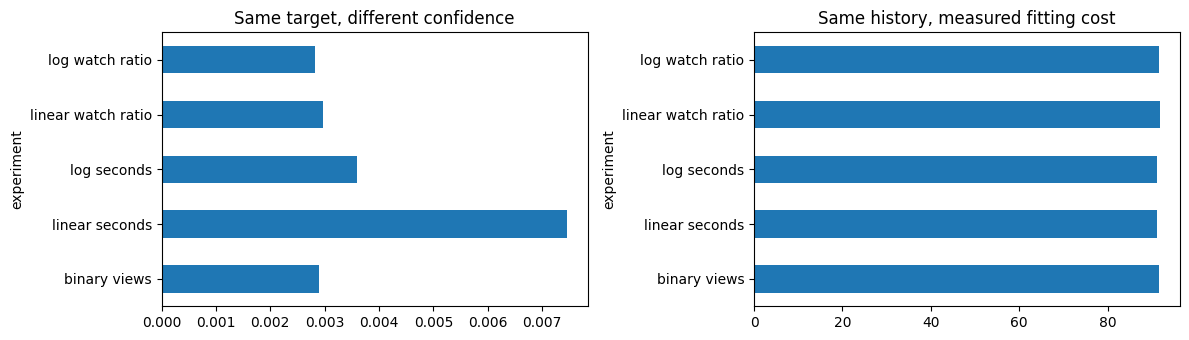

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
confidence_results.plot.barh(x="experiment", y="NDCG@10", ax=axes[0], legend=False)
confidence_results.plot.barh(x="experiment", y="fit seconds", ax=axes[1], legend=False)
axes[0].set_title("Same target, different confidence")
axes[1].set_title("Same history, measured fitting cost")
plt.tight_layout(); plt.show()


Signal transformations change the training objective. Uncompressed seconds
give long views much greater influence. Compare transformations using a common
future target, not by comparing losses computed with different confidence weights.

### Experiment 5. Alpha and regularization interact

Multiplying **all** confidence weights by $a$ is equivalent to replacing
$\lambda$ by $\lambda/a$. In $1+\alpha r$, however, only observed weights
change: the unobserved background remains at one. Alpha therefore also changes
the observed–unobserved balance.

Compare alpha values at fixed regularization, then regularization values at
fixed confidence.


In [27]:
for alpha in [1., 40.]:
    run_variant(f"ratio alpha={alpha:g}", "alpha", {"signal": "watch", "alpha": alpha})
for reg in [.01, 1.]:
    run_variant(f"ratio lambda={reg:g}", "regularization", {"signal": "watch"}, {"reg": reg})
display(pd.DataFrame(lab_rows).query("family in ['alpha', 'regularization']").set_index("experiment"))


ratio alpha=1 nnz 9,646,051 fit 92.41s {'Recall@10': 0.0010682348030561736, 'NDCG@10': 0.001060494700083788, 'Dislike@10': 0.0}
ratio alpha=40 nnz 9,646,051 fit 91.32s {'Recall@10': 0.004856613547141075, 'NDCG@10': 0.003334832564282254, 'Dislike@10': 0.0}
ratio lambda=0.01 nnz 9,646,051 fit 92.27s {'Recall@10': 0.0036470283697004496, 'NDCG@10': 0.002761203607902695, 'Dislike@10': 0.0}
ratio lambda=1 nnz 9,646,051 fit 91.69s {'Recall@10': 0.0036470283697004496, 'NDCG@10': 0.002626512117155045, 'Dislike@10': 0.0}


,family,fit seconds,retrieval seconds,Recall@10,NDCG@10,Dislike@10
experiment,,,,,,
ratio alpha=1,alpha,92.411997,1.053053,0.001068,0.001060,0.0
ratio alpha=40,alpha,91.319294,1.411226,0.004857,0.003335,0.0
ratio lambda=0.01,regularization,92.267588,1.061004,0.003647,0.002761,0.0
ratio lambda=1,regularization,91.688999,1.037465,0.003647,0.002627,0.0


### Experiment 6. Direct solves and a CG budget

CG approximates the minimum of a positive-definite quadratic. With
$\kappa=\lambda_{max}(A)/\lambda_{min}(A)$:

$$\|e_q\|_A\le2\left(\frac{\sqrt\kappa-1}{\sqrt\kappa+1}\right)^q\|e_0\|_A.$$

Compare direct solves with $q\in\{2,5,10\}$ CG steps using the same matrix,
dimension and eight epochs. Report unnormalized loss **on the same C**,
validation NDCG and fit time. Loss evaluation is outside the fit timer.


,solver,fit seconds,L on identical C,Recall@10,NDCG@10,Dislike@10
0,direct,130.421779,9.742528e+06,0.003484,0.003091,0.0
1,CG q=2,19.375462,9.836720e+06,0.003508,0.002431,0.0
2,CG q=5,36.926353,9.743274e+06,0.003484,0.003088,0.0
3,CG q=10,68.956241,9.742557e+06,0.003484,0.003091,0.0


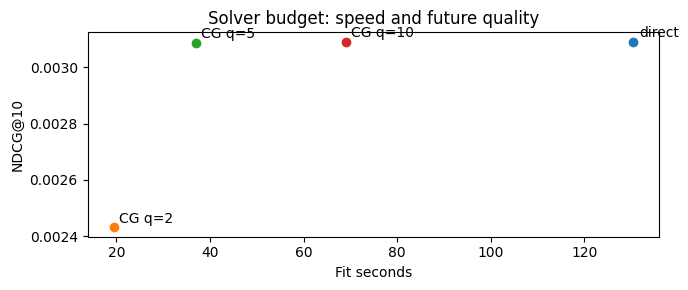

In [28]:
solver_rows = []
for label, options in [("direct", {"use_cg": False}),
                       ("CG q=2", {"use_cg": True, "cg_steps": 2}),
                       ("CG q=5", {"use_cg": True, "cg_steps": 5}),
                       ("CG q=10", {"use_cg": True, "cg_steps": 10})]:
    fitted, seconds, _ = fit_model(C_train["early"], iterations=8, **options)
    metrics = record_experiment(label, fitted, seconds, "solver")
    loss = als_loss(C_train["early"], fitted.user_factors.astype(float), fitted.item_factors.astype(float), REG)
    solver_rows.append({"solver": label, "fit seconds": seconds, "L on identical C": loss, **metrics})
solver_results = pd.DataFrame(solver_rows)
display(solver_results)
fig, ax = plt.subplots(figsize=(7, 3))
for row in solver_rows:
    ax.scatter(row["fit seconds"], row["NDCG@10"])
    ax.annotate(row["solver"], (row["fit seconds"], row["NDCG@10"]), xytext=(4, 3), textcoords="offset points")
ax.set(xlabel="Fit seconds", ylabel="NDCG@10", title="Solver budget: speed and future quality")
plt.tight_layout(); plt.show()


### Conditioning of a user's normal system

Increasing confidence can spread the spectrum of $A_u$. Measure
$\kappa(A_u)=\lambda_{max}(A_u)/\lambda_{min}(A_u)$ for fixed item factors
and several observed-weight scales. This diagnoses one local system; changing
alpha during full training also changes the factors themselves.


In [29]:
condition_Y = lab_models["CG q=5"].item_factors.astype(float)
condition_u = int(np.argmax(np.diff(C_train["early"].indptr)))
left, right = C_train["early"].indptr[condition_u:condition_u + 2]
local_Y = condition_Y[C_train["early"].indices[left:right]]
mass = (np.abs(C_train["early"].data[left:right]) - 1) / ALPHA
conditioning = []
for alpha in [1., 10., 40.]:
    normal = condition_Y.T @ condition_Y + local_Y.T @ ((alpha * mass)[:, None] * local_Y) + REG * np.eye(FACTORS)
    eigenvalues = np.linalg.eigvalsh(normal)
    conditioning.append({"observed-weight alpha": alpha, "smallest eigenvalue": eigenvalues[0],
                          "largest eigenvalue": eigenvalues[-1], "condition number": eigenvalues[-1] / eigenvalues[0]})
display(pd.DataFrame(conditioning))


,observed-weight alpha,smallest eigenvalue,largest eigenvalue,condition number
0,1.0,2.024011,15.629977,7.722280
1,10.0,2.625502,31.067648,11.833033
2,40.0,4.305732,85.616327,19.884269


### Experiment 7. Factor dimension and CPU threads

Sparse training can be limited by memory bandwidth, index access and uneven
row degrees as well as arithmetic. Repeat dimension timings and report the
median. The following runs process complete epochs; only dimension or the
number of worker threads changes.


In [30]:
resource_rows = []
for d in [16, 48, 96]:
    elapsed = []
    for repeat in range(2):
        fitted, seconds, _ = fit_model(C_train["early"], factors=d, iterations=5, seed=SEED + repeat)
        elapsed.append(seconds)
    resource_rows.append({"dimension": d, "median fit seconds": np.median(elapsed),
                          "min seconds": min(elapsed), "factor MiB":
                          (fitted.user_factors.nbytes + fitted.item_factors.nbytes) / 2**20})
display(pd.DataFrame(resource_rows))
thread_rows = []
for threads in [1, 2, 4]:
    _, seconds, _ = fit_model(C_train["early"], iterations=5, num_threads=threads)
    thread_rows.append({"threads": threads, "fit seconds": seconds})
display(pd.DataFrame(thread_rows))


,dimension,median fit seconds,min seconds,factor MiB
0,16,16.421914,16.136520,1.185303
1,48,23.002755,22.979937,3.555908
2,96,21.821546,21.725249,7.111816


,threads,fit seconds
0,1,29.285454
1,2,23.219427
2,4,23.263067


Factor dimension controls both capacity and operating cost. CG limits the
work per half-step, while additional threads need not produce linear speedup.
The resource comparison holds data and epoch count fixed. A larger factor
space is useful only if its quality gain justifies training, storage and
retrieval costs.


## 6. Batch training and periodic updates

| Mode | Input history | Updated factors |
|---|---|---|
| Row blocks | One fixed snapshot $C$ | Independent user rows with fixed $Y$ |
| Periodic full fit | Full history or a chosen window | All $X,Y$ from random initialization |
| Warm-start full fit | The same new snapshot | All $X,Y$ initialized from the previous model |
| Fold-in | Complete histories of selected users | Their $X$ with fixed $Y$ |
| Local alternating update | Complete rows of selected users/items | A partial approximation to the new global solution |

Cumulative history is $H_t=H_{t-1}\cup\Delta_t$. A rolling window uses
$H_t=\bigcup_{\tau=t-W+1}^{t}\Delta_\tau$. Recency weighting can use
$r_{ui}^{(t)}=\sum_{e\in H_t(u,i)}e^{-\gamma(t-t_e)}s_e$.
Rebuild preference and confidence after changing history or weights.
The first weekly comparison uses cumulative history without decay to isolate
the effect of initialization.

`partial_fit_users(ids, C[ids])` does **not** append events to stored history.
It solves a new user problem from the supplied row. Passing only $\Delta_t$
treats previous positive pairs as unobserved, with $c=1$. Updating item factors
also changes the Gram matrix and the optimal vectors of users without new events.

Keep ID mappings append-only and extend factors for new IDs. Sorting all raw
IDs again can silently assign an old factor row to a different entity. New
items need an item update or a content fallback; new users can be folded in
from their available history.

Evaluate snapshot $t$ on week $t+1$ using the catalog known at $t$. On the
same $C_t$, compare three random-start epochs, three warm-start epochs and
twenty random-start epochs. Warm update time excludes earlier training, so
also report cumulative time.

Catalogs, future targets and eligible users change across weeks. Compare
initialization methods within a week; a lower metric in a later week does
not by itself show that training on more history made the model worse.


,train through,evaluate week,mode,update seconds,warm cumulative seconds,loss on same C,users,warm-ID coverage,Recall@10,NDCG@10,Dislike@10
0,0,1,random / 3,0.92825,NaN,9.302885e+05,796,0.61663,0.02218,0.01413,0.00000
1,0,1,warm / 3,1.20415,1.20415,9.302885e+05,796,0.61663,0.02218,0.01413,0.00000
2,0,1,random / full,6.12153,NaN,8.917612e+05,796,0.61663,0.03421,0.02019,0.00000
3,1,2,random / 3,2.35344,NaN,2.126309e+06,884,0.58152,0.01584,0.00946,0.00023
4,1,2,warm / 3,2.12831,3.33246,2.075613e+06,884,0.58152,0.01923,0.01043,0.00000
5,1,2,random / full,14.88882,NaN,2.050965e+06,884,0.58152,0.01919,0.01067,0.00000
6,2,3,random / 3,3.69555,NaN,3.382687e+06,882,0.53331,0.02116,0.01253,0.00011
7,2,3,warm / 3,4.06658,7.39904,3.284079e+06,882,0.53331,0.01759,0.00969,0.00023
8,2,3,random / full,26.02340,NaN,3.277272e+06,882,0.53331,0.01766,0.01010,0.00034
9,3,4,random / 3,5.89298,NaN,4.550041e+06,1080,0.65442,0.00469,0.00372,0.00000


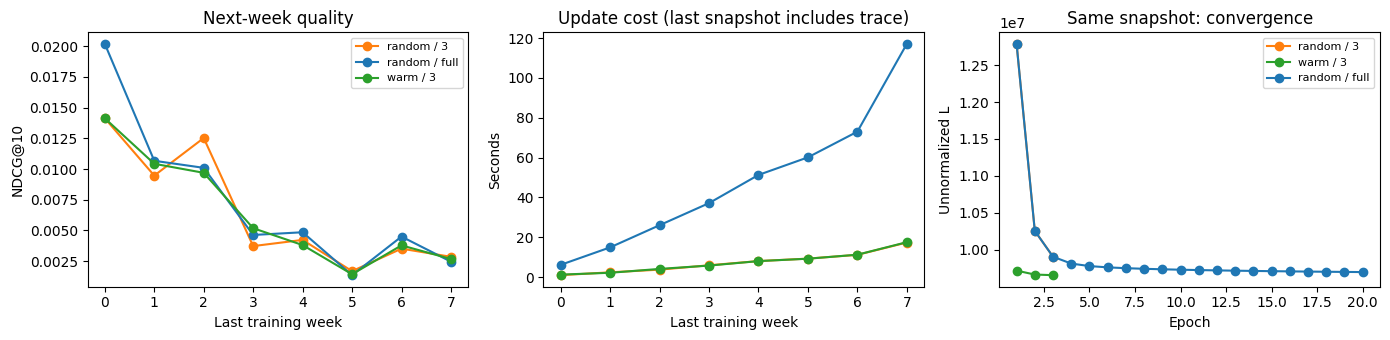

Trace calculation is included only in the last snapshot's times.


In [31]:
weekly_rows = []
warm_model = None
warm_total = 0.
weekly_traces = {}
for w in TRAIN_WEEKS:
    snapshot = train_events.filter(pl.col("week") <= w)
    matrices_w, seen_w = matrices(snapshot, registry, shape=shapes[w])
    C_w = matrices_w["early"]
    active_w = np.asarray(seen_w.sum(axis=0)).ravel() > 0
    cohort_w = eval_cohort[eval_cohort < shapes[w][0]]
    # The mapping is append-only; IDs outside this snapshot are excluded below.
    future = weeks[w + 1]
    partial_registry = Registry()
    partial_registry.users = {raw: idx for raw, idx in registry.users.items() if idx < shapes[w][0]}
    partial_registry.items = {raw: idx for raw, idx in registry.items.items() if idx < shapes[w][1]}
    target, bad, _, audit = future_targets(future, partial_registry, seen_w, cohort_w)
    experiments = [("random / 3", 3, None), ("warm / 3", 3, warm_model),
                   ("random / full", ITERATIONS, None)]
    for name, iterations, previous in experiments:
        fitted, seconds, trace = fit_model(C_w, iterations=iterations, initial=previous, trace=(w == TRAIN_WEEKS[-1]))
        if name == "warm / 3":
            warm_model = fitted
            warm_total += seconds
        rankings = retrieve(factor_scorer(fitted), sorted(target), seen_w, active_w)
        metrics = metric_rows(rankings, target, bad).mean().to_dict() if target else {}
        loss = als_loss(C_w, fitted.user_factors.astype(float), fitted.item_factors.astype(float), REG)
        weekly_rows.append({"train through": w, "evaluate week": w + 1, "mode": name,
                            "update seconds": seconds, "warm cumulative seconds": warm_total if name == "warm / 3" else np.nan,
                            "loss on same C": loss, "users": len(target),
                            "warm-ID coverage": audit["warm-ID coverage"], **metrics})
        if w == TRAIN_WEEKS[-1]:
            weekly_traces[name] = trace
weekly_results = pd.DataFrame(weekly_rows)
display(weekly_results.round(5))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
mode_colors = {"random / 3": "tab:orange", "warm / 3": "tab:green", "random / full": "tab:blue"}
for mode, frame in weekly_results.groupby("mode"):
    axes[0].plot(frame["train through"], frame["NDCG@10"], "o-", color=mode_colors[mode], label=mode)
    axes[1].plot(frame["train through"], frame["update seconds"], "o-", color=mode_colors[mode], label=mode)
for mode, trace in weekly_traces.items():
    axes[2].plot(np.arange(1, len(trace) + 1), trace, "o-", color=mode_colors[mode], label=mode)
axes[0].set(title="Next-week quality", xlabel="Last training week", ylabel="NDCG@10")
axes[1].set(title="Update cost (last snapshot includes trace)", xlabel="Last training week", ylabel="Seconds")
axes[2].set(title="Same snapshot: convergence", xlabel="Epoch", ylabel="Unnormalized L")
axes[0].legend(fontsize=8)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Trace calculation is included only in the last snapshot's times.")


In [32]:
# Actual partial-fit API: complete histories vs delta-only, with item factors frozen.
changed = np.unique(train_events.filter(pl.col("week") == TRAIN_WEEKS[-1])["u"].to_numpy())[:20]
delta_C, _ = matrices(train_events.filter(pl.col("week") == TRAIN_WEEKS[-1]), registry)
complete_update = copy.deepcopy(warm_model)
delta_update = copy.deepcopy(warm_model)
items_before = complete_update.item_factors.copy()
complete_update.partial_fit_users(changed, C_train["early"][changed])
delta_update.partial_fit_users(changed, delta_C["early"][changed])
np.testing.assert_array_equal(complete_update.item_factors, items_before)
expected = update_rows(C_train["early"][changed], items_before.astype(float), REG)
np.testing.assert_allclose(complete_update.user_factors[changed], expected, atol=2e-5)
print("||complete history update − delta-only update||:",
      np.linalg.norm(complete_update.user_factors[changed] - delta_update.user_factors[changed]))
print("Items frozen; complete-history partial update agrees with the normal equations.")


||complete history update − delta-only update||: 27.018684
Items frozen; complete-history partial update agrees with the normal equations.


### Updating active users every fifteen minutes

Keep event history or aggregates sufficient for the chosen window and decay.
Version the ID mapping, signal transformations and item factors. Reconstruct
each changed user's complete current row, then update its factor against
fixed items. Periodic joint updates refresh the catalog and all user factors.
A single new like is not a replacement for the user's history.


### Experiment 8. Full history, rolling windows and decay

$$r_{ui}^{(t)}=\sum_{e\in H(u,i)}s_e\,2^{-(t-t_e)/h},\qquad
c_{ui}^{(t)}=1+\alpha\log(1+r_{ui}^{(t)}).$$

The half-life $h$ is measured in weeks. An event $h$ weeks old contributes
half its original mass. A window removes old events from the training
objective; decay retains a weaker contribution. Historical impressions remain
excluded from recommendations in both cases.

Measure future quality, sparse storage and fit time on the same validation
week. Select the window or half-life using validation only.


In [33]:
history_options = [
    ("all history", {}), ("last 2 weeks", {"window": 2}),
    ("last 4 weeks", {"window": 4}), ("half-life 1 week", {"half_life": 1.}),
    ("half-life 4 weeks", {"half_life": 4.}),
]
history_sizes = []
for name, options in history_options:
    specification = {"signal": "early", **options}
    run_variant(name, "history", specification)
    C = matrix_from_events(train_events, registry, **specification)
    history_sizes.append({"experiment": name, "nnz": C.nnz,
                          "CSR MiB": (C.data.nbytes + C.indices.nbytes + C.indptr.nbytes) / 2**20})
history_results = pd.DataFrame(lab_rows).query("family == 'history'").merge(pd.DataFrame(history_sizes), on="experiment")
display(history_results.set_index("experiment"))


all history nnz 9,646,051 fit 91.42s {'Recall@10': 0.0029040966361004936, 'NDCG@10': 0.0024523290305478638, 'Dislike@10': 0.0}
last 2 weeks nnz 3,283,149 fit 30.88s {'Recall@10': 0.007464340686459633, 'NDCG@10': 0.006151184871389122, 'Dislike@10': 0.0}
last 4 weeks nnz 5,683,590 fit 52.90s {'Recall@10': 0.0051299926471742585, 'NDCG@10': 0.004152851377792425, 'Dislike@10': 0.0}
half-life 1 week nnz 9,646,051 fit 91.06s {'Recall@10': 0.005449149313728814, 'NDCG@10': 0.0039215505940851, 'Dislike@10': 0.0}
half-life 4 weeks nnz 9,646,051 fit 91.57s {'Recall@10': 0.004253929910040166, 'NDCG@10': 0.0030734571207010667, 'Dislike@10': 0.0}


,family,fit seconds,retrieval seconds,Recall@10,NDCG@10,Dislike@10,nnz,CSR MiB
experiment,,,,,,,,
all history,history,91.424076,1.039738,0.002904,0.002452,0.0,9646051,73.631680
last 2 weeks,history,30.877680,1.002494,0.007464,0.006151,0.0,3283149,25.086590
last 4 weeks,history,52.902057,1.026754,0.005130,0.004153,0.0,5683590,43.400501
half-life 1 week,history,91.064985,1.041017,0.005449,0.003922,0.0,9646051,73.631680
half-life 4 weeks,history,91.574267,1.030848,0.004254,0.003073,0.0,9646051,73.631680


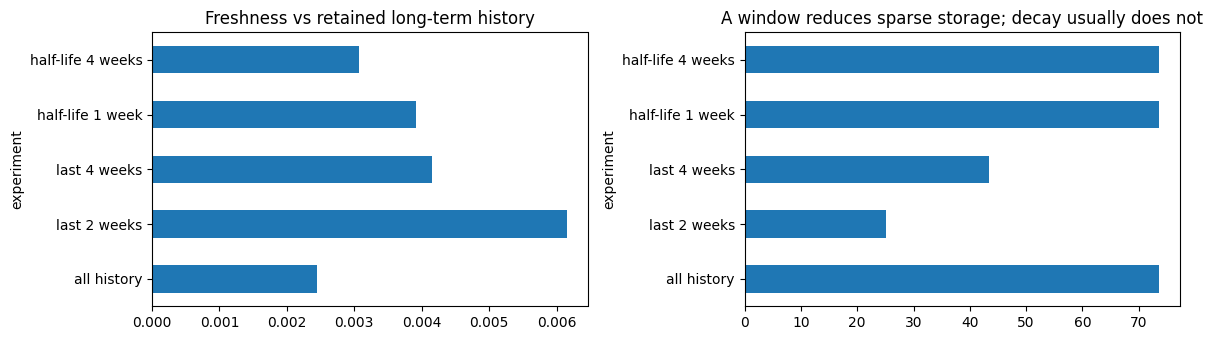

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
history_results.plot.barh(x="experiment", y="NDCG@10", legend=False, ax=axes[0])
history_results.plot.barh(x="experiment", y="CSR MiB", legend=False, ax=axes[1])
axes[0].set_title("Freshness vs retained long-term history")
axes[1].set_title("A window reduces sparse storage; decay usually does not")
plt.tight_layout(); plt.show()


Decay changes the strength of evidence; a window also reduces stored history.
The shared seen-filter prevents a shorter window from gaining an artificial
advantage by recommending previously shown videos.

### Experiment 9. Complete-history and delta-only fold-in

With fixed $Y$, complete-history fold-in minimizes the user's original
quadratic objective. Delta-only fold-in solves a different problem:

$$x_u^{\Delta}=\arg\min_x\sum_i c_{ui}^{\Delta}(p_{ui}^{\Delta}-x^\top y_i)^2+\lambda\|x\|^2.$$

Compare the stale previous-week model, complete-history fold-in, delta-only
fold-in and a joint warm update of users and items. Catalog, seen-filter and
eligible validation users stay the same.


In [35]:
previous_events = train_events.filter(pl.col("week") < TRAIN_WEEKS[-1])
previous_C = matrix_from_events(previous_events, registry, signal="early")
previous_model, previous_seconds, _ = fit_model(previous_C)
record_experiment("stale model", previous_model, previous_seconds, "incremental")
complete = copy.deepcopy(previous_model)
delta_only = copy.deepcopy(previous_model)
users_changed = np.unique(train_events.filter(pl.col("week") == TRAIN_WEEKS[-1])["u"].to_numpy())
current_C = matrix_from_events(train_events, registry, signal="early")
last_C = matrix_from_events(train_events.filter(pl.col("week") == TRAIN_WEEKS[-1]), registry, signal="early")
for label, model, source in [("complete fold-in", complete, current_C), ("delta-only fold-in", delta_only, last_C)]:
    begin = perf_counter(); model.partial_fit_users(users_changed, source[users_changed])
    seconds = perf_counter() - begin
    record_experiment(label, model, seconds, "incremental")
joint_update, seconds, _ = fit_model(current_C, initial=previous_model, iterations=5)
record_experiment("warm joint / 5", joint_update, seconds, "incremental")
display(pd.DataFrame(lab_rows).query("family == 'incremental'").set_index("experiment"))


,family,fit seconds,retrieval seconds,Recall@10,NDCG@10,Dislike@10
experiment,,,,,,
stale model,incremental,76.435968,0.968979,0.000542,0.000798,0.0
complete fold-in,incremental,8.023119,0.963966,0.001230,0.001316,0.0
delta-only fold-in,incremental,1.263254,0.987755,0.001807,0.001307,0.0
warm joint / 5,incremental,22.651855,1.046386,0.003631,0.002536,0.0


### Publishing factors and a retrieval index

A weekly pipeline fixes the event cutoff, ID dictionaries and signal version.
User and item half-steps read consistent factor generations. Publish
$(X^{(v)},Y^{(v)},\mathrm{index}(Y^{(v)}))$ together. Mixing a new query vector
with an unrelated item-index generation changes the scoring model.

For distributed ALS, $Y^\top Y=\sum_jY_j^\top Y_j$: each shard contributes a
$d\times d$ Gram matrix. A user update also needs the item factors referenced
by its sparse row. Communication and skewed row degrees can dominate runtime.
Sharding does not remove the need for a consistent Gram matrix and fixed item
factors throughout a user half-step.


### Experiment 10. One new like as a rank-one update

With fixed $Y$, a previously unobserved positive pair with confidence $c$
changes the system to $A'=A+(c-1)yy^\top$, $b'=b+cy$.
Sherman–Morrison gives:

$$v=A^{-1}y,\quad z=A^{-1}(b+cy),\qquad
x'=z-\frac{(c-1)v(y^\top z)}{1+(c-1)y^\top v}.$$

If the Cholesky factorization of $A$ is already available, the two triangular
solves cost $O(d^2)$. Simulate a hypothetical new like without future labels
and check equality with a full solve.

Caching a factorization for every user costs $O(md^2)$, and changing item
factors invalidates the cached systems. This is a local fold-in optimization.


In [36]:
def rank_one_update(A, b, y, confidence):
    from scipy.linalg import cho_factor, cho_solve
    factor = cho_factor(A, lower=True)
    v = cho_solve(factor, y)
    z = cho_solve(factor, b + confidence * y)
    delta = confidence - 1.
    return z - delta * v * (y @ z) / (1. + delta * (y @ v))


fixed_Y = previous_model.item_factors.astype(float)
u = int(users_changed[0])
left, right = previous_C.indptr[u:u + 2]
ids, signed = previous_C.indices[left:right], previous_C.data[left:right]
local = fixed_Y[ids]
A = fixed_Y.T @ fixed_Y + local.T @ ((np.abs(signed) - 1)[:, None] * local) + REG * np.eye(FACTORS)
b = local.T @ np.where(signed > 0, np.abs(signed), 0.)
new_i = int(np.setdiff1d(np.flatnonzero(active_train), ids)[0])
y, c = fixed_Y[new_i], 11.
rank_one_x = rank_one_update(A, b, y, c)
full_x = np.linalg.solve(A + (c - 1) * np.outer(y, y), b + c * y)
np.testing.assert_allclose(rank_one_x, full_x, atol=1e-8)
print("Rank-one update matches full solve; max |difference| =", np.max(np.abs(rank_one_x - full_x)))
print("Hypothetical liked-item score:", float(np.linalg.solve(A, b) @ y), "→", float(rank_one_x @ y))


Rank-one update matches full solve; max |difference| = 3.9968028886505635e-15
Hypothetical liked-item score: -0.08306933557862738 → -0.06977015412307094


## 7. Combining signals before or after training

**Early fusion** builds $r_{ui}=\log(1+\sum_s a_sS^{(s)}_{ui})$ and trains
one model $L(C(r),P(r))$. It uses one pair of factor matrices and one retrieval
path, but compresses distinct intents into a shared signal and factor space.

**Independent ALS** learns $(X^{(s)},Y^{(s)})$ for each signal. Channels can
have different dimensions, regularization, confidence scales and history
windows. We keep these settings equal in the main comparison. Sparse actions
can leave a user without positive observations; its exact minimizing user
factor is then zero, so a fallback may be necessary.

Do not average factor coordinates across independent models. For an orthogonal
$Q_s$, $X_sQ_s,Y_sQ_s$ preserve all scores while changing the coordinate basis.
Combine scores, ranks or matched concatenations instead.

$$\operatorname{ALS}\!\left(\sum_s a_sS_s\right)
\ne\sum_s a_s\operatorname{ALS}(S_s)$$

Factorization is nonlinear in the input, especially after thresholds,
logarithms and conflict handling. Three 48-dimensional models also have more
parameters than one 48-dimensional model. We include equal-capacity controls.


In [37]:
models, fit_times = {}, {}
for name in [*CHANNELS, "early"]:
    models[name], fit_times[name], _ = fit_model(C_train[name])
    positive_users = np.unique(C_train[name].tocoo().row[C_train[name].tocoo().data > 0]).size
    print(name, f"{fit_times[name]:.2f}s", f"users with a positive signal: {positive_users}/{registry.shape[0]}")

popular = np.asarray(seen_train.sum(axis=0)).ravel().astype(float)
pop_scorer = lambda users, items: np.broadcast_to(popular[items], (len(users), len(items)))
valid_rankings = {name: retrieve(factor_scorer(model), sorted(ground_valid), seen_train, active_train)
                  for name, model in models.items()}
valid_rankings["popularity"] = retrieve(pop_scorer, sorted(ground_valid), seen_train, active_train)
valid_metrics = {name: metric_rows(ranking, ground_valid, bad_valid).mean().to_dict()
                 for name, ranking in valid_rankings.items()}
display(pd.DataFrame(valid_metrics).T.sort_values("NDCG@10", ascending=False))


watch 91.11s users with a positive signal: 10000/10000
like 1.54s users with a positive signal: 6262/10000
actions 0.85s users with a positive signal: 5129/10000
early 91.99s users with a positive signal: 10000/10000


,Recall@10,NDCG@10,Dislike@10
like,0.005951,0.005211,0.000071
actions,0.003382,0.002870,0.000000
watch,0.003765,0.002820,0.000000
early,0.002904,0.002452,0.000000
popularity,0.001758,0.001458,0.000142


### Experiment 11. Dislikes, skips and missing feedback

Compare four policies for the same early-fusion mass: ignore explicit dislikes;
use dislikes with $p=0,c=11$; use stronger dislikes with $p=0,c=41$; and add a
weak negative target $p=0,c=3$ for quick skips with $w<0.1$.

Treating a quick skip as weak negative evidence is a separate hypothesis.
It is not equivalent to observing an explicit dislike. All policies use the
same impressions and ranking rules.


In [38]:
negative_grid = [
    ("ignore dislikes", {"negative_weight": 0.}),
    ("explicit dislike c=11", {"negative_weight": 10.}),
    ("explicit dislike c=41", {"negative_weight": 40.}),
    ("dislike + weak skips", {"negative_weight": 10., "skip_weight": 2.}),
]
for name, options in negative_grid:
    run_variant(name, "negative", {"signal": "early", **options})
negative_results = pd.DataFrame(lab_rows).query("family == 'negative'")
display(negative_results.set_index("experiment"))


ignore dislikes nnz 9,642,008 fit 91.96s {'Recall@10': 0.002692822324676207, 'NDCG@10': 0.0025301733946406705, 'Dislike@10': 0.0}
explicit dislike c=11 nnz 9,646,051 fit 92.01s {'Recall@10': 0.0029040966361004936, 'NDCG@10': 0.0024523290305478638, 'Dislike@10': 0.0}
explicit dislike c=41 nnz 9,646,051 fit 97.76s {'Recall@10': 0.0025546178455285516, 'NDCG@10': 0.0024157903712212045, 'Dislike@10': 0.0}
dislike + weak skips nnz 9,646,051 fit 99.22s {'Recall@10': 0.004200963343008509, 'NDCG@10': 0.0036448042761890124, 'Dislike@10': 0.0}


,family,fit seconds,retrieval seconds,Recall@10,NDCG@10,Dislike@10
experiment,,,,,,
ignore dislikes,negative,91.959078,1.261749,0.002693,0.002530,0.0
explicit dislike c=11,negative,92.012038,1.096819,0.002904,0.002452,0.0
explicit dislike c=41,negative,97.760009,1.052081,0.002555,0.002416,0.0
dislike + weak skips,negative,99.223903,1.050357,0.004201,0.003645,0.0


Rare dislikes can produce zero Dislike@10 for every model. That makes the
metric uninformative on this cohort; it does not establish equal safety.
Also inspect scores on observed validation actions, dislikes and other shown
videos. These comparisons remain conditional on the historical exposure policy.


In [39]:
observed_valid = registry.encode(weeks[VALID_WEEK]).drop_nulls(["u", "i"])
observed_valid = observed_valid.filter(pl.col("u").is_in(eval_cohort.tolist()))
observed_score_rows = []
for label in ["ignore dislikes", "explicit dislike c=11", "explicit dislike c=41", "dislike + weak skips"]:
    fitted = lab_models[label]
    uu, ii = observed_valid["u"].to_numpy(), observed_valid["i"].to_numpy()
    values = np.einsum("ij,ij->i", fitted.user_factors[uu], fitted.item_factors[ii])
    is_positive = (observed_valid["like"] | observed_valid["share"] | observed_valid["bookmark"]).to_numpy()
    is_negative = observed_valid["dislike"].to_numpy()
    for category, mask in [("positive action", is_positive & ~is_negative),
                            ("dislike", is_negative), ("other shown", ~is_positive & ~is_negative)]:
        observed_score_rows.append({"policy": label, "observed category": category,
                                    "count": int(mask.sum()),
                                    "mean score": float(values[mask].mean()) if mask.any() else np.nan})
display(pd.DataFrame(observed_score_rows))


,policy,observed category,count,mean score
0,ignore dislikes,positive action,6557,0.296559
1,ignore dislikes,dislike,306,0.195539
2,ignore dislikes,other shown,501446,0.264726
3,explicit dislike c=11,positive action,6557,0.296476
4,explicit dislike c=11,dislike,306,0.177766
5,explicit dislike c=11,other shown,501446,0.264589
6,explicit dislike c=41,positive action,6557,0.296191
7,explicit dislike c=41,dislike,306,0.159005
8,explicit dislike c=41,other shown,501446,0.264280
9,dislike + weak skips,positive action,6557,0.255186


### Experiment 12. One ALS-144 versus three ALS-48 models

$$\mathrm{params}_{\mathrm{early}}=(m+n)D,\qquad
\mathrm{params}_{\mathrm{late}}=(m+n)\sum_sd_s.$$

Three ALS-48 models store the same number of factor parameters as one ALS-144.
Compare quality, memory and fit time explicitly. Equal parameter counts do
not imply equal computation: direct-solver costs grow quadratically and
cubically with dimension, and channel sparsity differs.


In [40]:
wide_early, wide_seconds, _ = fit_model(C_train["early"], factors=3 * FACTORS)
record_experiment("early / equal total dimension", wide_early, wide_seconds, "capacity",
                  {"matrix": {"signal": "early"}, "fit": {"factors": 3 * FACTORS}})
small_models = {}
for signal in CHANNELS:
    small_models[signal], seconds, _ = fit_model(C_train[signal], factors=FACTORS // 3)
capacity_table = pd.DataFrame([
    {"architecture": f"one early-{FACTORS}", "factor MiB":
     (models["early"].user_factors.nbytes + models["early"].item_factors.nbytes) / 2**20,
     "fit seconds": fit_times["early"]},
    {"architecture": f"one early-{3 * FACTORS}", "factor MiB":
     (wide_early.user_factors.nbytes + wide_early.item_factors.nbytes) / 2**20, "fit seconds": wide_seconds},
    {"architecture": f"three ALS-{FACTORS}", "factor MiB":
     sum(m.user_factors.nbytes + m.item_factors.nbytes for s, m in models.items() if s in CHANNELS) / 2**20,
     "fit seconds": sum(fit_times[s] for s in CHANNELS)},
])
display(capacity_table)


,architecture,factor MiB,fit seconds
0,one early-48,3.555908,91.986961
1,one early-144,10.667725,128.002925
2,three ALS-48,10.667725,93.505382


Increasing dimension has a different cost for sparse actions and dense views.
Independent channels can allocate capacity to rare actions, while one wide
model must explain the merged signal in a common space. The score-fusion
comparison below evaluates both equal-capacity pairs.


## 8. Score scales, normalization and mixture weights

For channel scores $f_s(u,i)=x_u^{(s)\top}y_i^{(s)}$, use
$F(u,i)=\sum_s\beta_sf_s(u,i)$ with $\beta_s\ge0$ and $\sum_s\beta_s=1$.
Equal weights do not imply equal influence: label frequency, confidence and
regularization change score scales. An ALS score is not a probability of a like.

Normalize each channel using the user's score distribution over the training
catalog $J$, including seen items that will subsequently be masked:

$$\mu_{us}=\frac1{|J|}\sum_{i\in J}f_s(u,i),\qquad
\sigma_{us}^2=\frac1{|J|}\sum_{i\in J}f_s(u,i)^2-\mu_{us}^2,$$
$$z_s(u,i)=\frac{f_s(u,i)-\mu_{us}}{\max(\sigma_{us},\varepsilon)},\qquad
F_z=\sum_s\beta_sz_s.$$

No full score matrix is needed:
$\mu_{us}=x_u^\top\bar y_s$ and
$\mathbb E[f_s^2]=x_u^\top(Y_{s,J}^\top Y_{s,J}/|J|)x_u$.
Disable a channel when variance is nearly zero rather than amplifying noise.
Z-scores align scales; probability calibration would require separate labels
and a calibration split or out-of-fold predictions.

Choose weights by validation **NDCG@10 for future positive actions**, then
freeze them. Recompute training-only moments after the final refit without
using test feedback. A learned stacking model would similarly need chronological
out-of-fold scores rather than in-sample predictions.


In [41]:
def normalization_stats(model, active, epsilon=1e-6):
    X, Y = model.user_factors.astype(float), model.item_factors[active].astype(float)
    mean = X @ Y.mean(axis=0)
    second = np.einsum("ud,df,uf->u", X, Y.T @ Y / len(Y), X)
    std = np.sqrt(np.maximum(second - mean**2, 0.))
    inverse_std = np.divide(1., std, out=np.zeros_like(std), where=std > epsilon)
    return mean, inverse_std


def blend_scorer(model_dict, weights, active, normalize=True):
    statistics = {s: normalization_stats(model_dict[s], active) for s in CHANNELS} if normalize else {}

    def score(users, items):
        total = np.zeros((len(users), len(items)))
        for signal, weight in zip(CHANNELS, weights):
            model = model_dict[signal]
            part = model.user_factors[users] @ model.item_factors[items].T
            if normalize:
                mean, inverse = statistics[signal]
                part = (part - mean[users, None]) * inverse[users, None]
            total += weight * part
        return total

    return score


equal_weights = np.full(3, 1/3)
raw_rankings = retrieve(blend_scorer(models, equal_weights, active_train, normalize=False),
                        sorted(ground_valid), seen_train, active_train)
valid_rankings["raw equal blend"] = raw_rankings
weight_grid = [(1., 0., 0.), (0., 1., 0.), (0., 0., 1.), (1/3, 1/3, 1/3),
               (.5, .25, .25), (.25, .5, .25), (.25, .25, .5)]
selection = []
blend_grid_rankings = {}
best_weights, best_ndcg, best_ranking = None, -np.inf, None
for weights in weight_grid:
    ranking = retrieve(blend_scorer(models, weights, active_train), sorted(ground_valid), seen_train, active_train)
    blend_grid_rankings[tuple(weights)] = ranking
    metrics = metric_rows(ranking, ground_valid, bad_valid).mean().to_dict()
    selection.append({"weights (watch, like, actions)": weights, **metrics})
    if metrics["NDCG@10"] > best_ndcg:
        best_weights, best_ndcg, best_ranking = weights, metrics["NDCG@10"], ranking
valid_rankings["z blend / selected"] = best_ranking
display(pd.DataFrame(selection).sort_values("NDCG@10", ascending=False))
print("Frozen validation-selected weights:", best_weights)


,"weights (watch, like, actions)",Recall@10,NDCG@10,Dislike@10
5,"(0.25, 0.5, 0.25)",0.006051,0.005506,0.000000
1,"(0.0, 1.0, 0.0)",0.005951,0.005211,0.000000
6,"(0.25, 0.25, 0.5)",0.006459,0.005204,0.000071
3,"(0.3333333333333333, 0.3333333333333333, 0.333...",0.005730,0.005018,0.000071
4,"(0.5, 0.25, 0.25)",0.005379,0.004436,0.000071
2,"(0.0, 0.0, 1.0)",0.003382,0.002870,0.000000
0,"(1.0, 0.0, 0.0)",0.003765,0.002820,0.000000


Frozen validation-selected weights: (0.25, 0.5, 0.25)


### Rank fusion and candidate unions

Reciprocal Rank Fusion combines rank positions instead of raw score scales:

$$F_{\rm RRF}(u,i)=\sum_{s:i\in T_s(u)}\frac{\beta_s}{a+\operatorname{rank}_s(u,i)},\qquad a=60.$$

Each $T_s$ is a source's top-$L$ list, ranks start at one and missing candidates
contribute zero. We fix equal weights, $a=60$ and $L=50$ for the main comparison.
RRF only ranks the union $\mathcal C_u=\bigcup_sT_s(u)$.

$$\operatorname{CandidateRecall}_u=
\frac{|\mathcal C_u\cap G_u|}{|G_u|}.$$

Candidate recall bounds the recall of any reranker on this union. The top-K
oracle is further bounded by $\min(K,|\mathcal C_u\cap G_u|)/|G_u|$.
A full-catalog score mixture can retrieve an item outside every source's top-L.


In [42]:
CANDIDATES = 50
channel_candidates = {
    s: retrieve(factor_scorer(models[s]), sorted(ground_valid), seen_train, active_train, k=CANDIDATES)
    for s in CHANNELS
}
valid_rankings["RRF / equal"] = {
    u: rrf([channel_candidates[s][u] for s in CHANNELS], equal_weights, K)
    for u in ground_valid
}
candidate_recall = []
oracle_at_k = []
for u, relevant in ground_valid.items():
    union = set().union(*(set(channel_candidates[s][u]) for s in CHANNELS))
    hits = len(union & relevant)
    candidate_recall.append(hits / len(relevant))
    oracle_at_k.append(min(K, hits) / len(relevant))
print("Validation candidate union recall:", np.mean(candidate_recall))
print("Validation oracle Recall@10 on union:", np.mean(oracle_at_k))
display(pd.DataFrame({name: metric_rows(r, ground_valid, bad_valid).mean()
                      for name, r in valid_rankings.items()}).T.sort_values("NDCG@10", ascending=False))


Validation candidate union recall: 0.05566194954984332
Validation oracle Recall@10 on union: 0.05566194954984332


,Recall@10,NDCG@10,Dislike@10
z blend / selected,0.006051,0.005506,0.000000
like,0.005951,0.005211,0.000071
RRF / equal,0.004709,0.003725,0.000071
raw equal blend,0.003843,0.003695,0.000000
actions,0.003382,0.002870,0.000000
watch,0.003765,0.002820,0.000000
early,0.002904,0.002452,0.000000
popularity,0.001758,0.001458,0.000142


### One retrieval index for a linear mixture

For nonnegative weights, concatenate matched user and item factors:

$$\tilde x_u=[\sqrt{\beta_1}x_u^{(1)};\ldots;\sqrt{\beta_S}x_u^{(S)}],\quad
\tilde y_i=[\sqrt{\beta_1}y_i^{(1)};\ldots;\sqrt{\beta_S}y_i^{(S)}].$$

Then **$\tilde x_u^\top\tilde y_i=\sum_s\beta_sf_s(u,i)$**. A single
maximum-inner-product index represents the mixture, but its dimension is
$D=\sum_sd_s$. Normalizing item vectors for cosine search would change the ranking.

For the z-score mixture, keep item blocks $\sqrt{\beta_s}y_i^{(s)}$ and use
query blocks $\sqrt{\beta_s}x_u^{(s)}/\sigma_{us}$.
The offset $-\sum_s\beta_s\mu_{us}/\sigma_{us}$ is constant across items.
User-dependent weights can be placed entirely in the query, keeping the item
index fixed. Arbitrary item-dependent weights or nonlinear rerankers need not
admit this representation.

Averaging factors introduces unwanted cross-terms:

$\bar x^\top\bar y=\tfrac14(x_1^\top y_1+x_1^\top y_2+x_2^\top y_1+x_2^\top y_2)$
for $\bar x=(x_1+x_2)/2$, $\bar y=(y_1+y_2)/2$.
Use $[x_1;x_2]/\sqrt2$ and $[y_1;y_2]/\sqrt2$ for the average score instead.


In [43]:
# Check the identity on a small slice, avoiding an extra full copy of all factors.
factor_pairs = [(models[s].user_factors[:8].astype(float),
                 models[s].item_factors[:20].astype(float)) for s in CHANNELS]
XX, YY = concat_factors(factor_pairs, best_weights)
direct = sum(w * X @ Y.T for w, (X, Y) in zip(best_weights, factor_pairs))
np.testing.assert_allclose(XX @ YY.T, direct, atol=1e-10)

u = int(sorted(ground_valid)[0])
query_parts, item_parts, offset = [], [], 0.
for signal, weight in zip(CHANNELS, best_weights):
    mean, inverse = normalization_stats(models[signal], active_train)
    query_parts.append(np.sqrt(weight) * models[signal].user_factors[u].astype(float) * inverse[u])
    item_parts.append(np.sqrt(weight) * models[signal].item_factors[:20].astype(float))
    offset += weight * mean[u] * inverse[u]
normalized_dot = np.concatenate(query_parts) @ np.concatenate(item_parts, axis=1).T - offset
np.testing.assert_allclose(normalized_dot,
    blend_scorer(models, best_weights, active_train)(np.array([u]), np.arange(20))[0], atol=1e-5)
print("Raw score identity and z-score retrieval identity verified.")


Raw score identity and z-score retrieval identity verified.


### Experiment 13. Equal capacity and user-dependent weights

Compare three ALS-16 models with one ALS-48, then three ALS-48 models with one
ALS-144. Next, disable the actions channel for users without historical
positive actions and renormalize the remaining weights:

$$\beta_{us}=\frac{\beta_sa_{us}}{\sum_j\beta_ja_{uj}},\qquad
a_{u,\mathrm{actions}}=\mathbf1[\#\mathrm{actions}_u>0].$$

Activity is computed from training only. Compare this gate with the global
mixture on the same validation users. A zero factor supplies no personalized
evidence for that channel.


In [44]:
small_blend_ranking = retrieve(blend_scorer(small_models, equal_weights, active_train),
                               sorted(ground_valid), seen_train, active_train)
capacity_quality = pd.DataFrame([
    {"architecture": f"early-{FACTORS}", **valid_metrics["early"]},
    {"architecture": f"3 x {FACTORS // 3} z blend", **metric_rows(small_blend_ranking, ground_valid, bad_valid).mean()},
    {"architecture": f"early-{3 * FACTORS}", **metric_rows(lab_rankings["early / equal total dimension"], ground_valid, bad_valid).mean()},
    {"architecture": f"3 x {FACTORS} z blend", **metric_rows(best_ranking, ground_valid, bad_valid).mean()},
])
display(capacity_quality)


def gated_scorer(model_dict, weights, active, positive_actions):
    stats = {s: normalization_stats(model_dict[s], active) for s in CHANNELS}
    gate = np.tile(weights, (model_dict["watch"].user_factors.shape[0], 1)).astype(float)
    gate[positive_actions == 0, 2] = 0.
    sums = gate.sum(axis=1, keepdims=True)
    gate = np.divide(gate, sums, out=np.tile([1., 0., 0.], (len(gate), 1)), where=sums > 0)

    def score(users, items):
        total = np.zeros((len(users), len(items)))
        for col, signal in enumerate(CHANNELS):
            mean, inverse = stats[signal]
            raw = model_dict[signal].user_factors[users] @ model_dict[signal].item_factors[items].T
            total += gate[users, col, None] * (raw - mean[users, None]) * inverse[users, None]
        return total

    return score


train_action_counts = np.asarray((C_train["actions"] > 0).sum(axis=1)).ravel()
gated_valid = retrieve(gated_scorer(models, best_weights, active_train, train_action_counts),
                       sorted(ground_valid), seen_train, active_train)
valid_rankings["z blend / action gate"] = gated_valid
display(pd.DataFrame({"global z": metric_rows(best_ranking, ground_valid, bad_valid).mean(),
                      "action-aware z": metric_rows(gated_valid, ground_valid, bad_valid).mean()}).T)


,architecture,Recall@10,NDCG@10,Dislike@10
0,early-48,0.002904,0.002452,0.000000
1,3 x 16 z blend,0.006146,0.005016,0.000071
2,early-144,0.001758,0.001710,0.000000
3,3 x 48 z blend,0.006051,0.005506,0.000000


,Recall@10,NDCG@10,Dislike@10
global z,0.006051,0.005506,0.0
action-aware z,0.006051,0.005506,0.0


### Experiment 14. Completion and deliberate actions are different objectives

The same mixture weights can rank future completions and future actions
differently. Evaluate both targets on the intersection of their eligible
users, keeping the audience fixed. A mixture is dominated if another mixture
improves both metrics.

$$\beta^*=\arg\max_\beta\{\theta\,\mathrm{NDCG}_{actions}(\beta)
 +(1-\theta)\,\mathrm{NDCG}_{completion}(\beta)\}.$$

This exposes a product trade-off. Our primary selection criterion remains
future actions; the second objective does not change the frozen protocol.


,weights,action NDCG,completion NDCG
0,"(1.0, 0.0, 0.0)",0.002820,0.013771
1,"(0.0, 1.0, 0.0)",0.005211,0.012650
2,"(0.0, 0.0, 1.0)",0.002870,0.010341
3,"(0.3333333333333333, 0.3333333333333333, 0.333...",0.005018,0.015796
4,"(0.5, 0.25, 0.25)",0.004436,0.015513
5,"(0.25, 0.5, 0.25)",0.005506,0.015583
6,"(0.25, 0.25, 0.5)",0.005204,0.015778


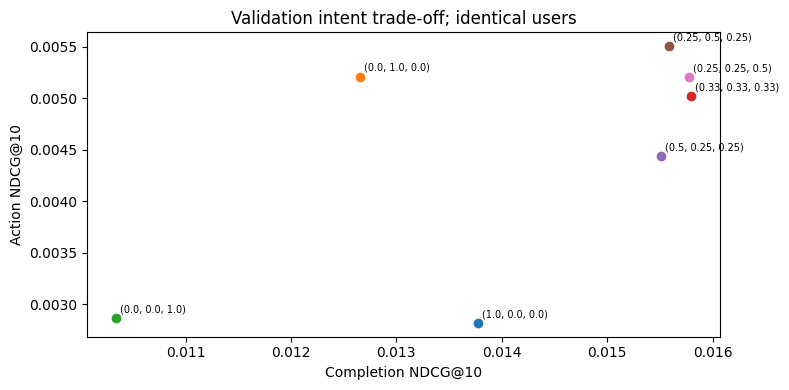

Common eligible users: 1412


In [45]:
common_intent_users = sorted(set(ground_valid) & set(long_valid))
tradeoff_rows = []
if common_intent_users:
    actions_target = {u: ground_valid[u] for u in common_intent_users}
    completion_target = {u: long_valid[u] for u in common_intent_users}
    for weights, ranking in blend_grid_rankings.items():
        tradeoff_rows.append({"weights": weights,
                              "action NDCG": metric_rows(ranking, actions_target).mean()["NDCG@10"],
                              "completion NDCG": metric_rows(ranking, completion_target).mean()["NDCG@10"]})
    tradeoff_results = pd.DataFrame(tradeoff_rows)
    display(tradeoff_results)
    fig, ax = plt.subplots(figsize=(8, 4))
    for row in tradeoff_rows:
        ax.scatter(row["completion NDCG"], row["action NDCG"])
        ax.annotate(str(tuple(round(x, 2) for x in row["weights"])),
                     (row["completion NDCG"], row["action NDCG"]), xytext=(3, 4), textcoords="offset points", fontsize=7)
    ax.set(xlabel="Completion NDCG@10", ylabel="Action NDCG@10", title="Validation intent trade-off; identical users")
    plt.tight_layout(); plt.show()
    print("Common eligible users:", len(common_intent_users))


### Experiment 15. Candidate loss before reranking

Retrieve top-$L$ from each source, merge the lists and rescore the union.
Compare RRF, score reranking and full-catalog score ranking on the same users.

$$\operatorname{OracleRecall@K}( C_u)=
\frac{\min(K,| C_u\cap G_u|)}{|G_u|}.$$

Increasing $L$ changes candidate coverage, scoring work and latency. No reranker
can recover a relevant video that the candidate stage omitted. A linear score
mixture's exact top-K need not lie in the union of individual top-L lists.


,L per source,mean union size,candidate recall,oracle Recall@10,RRF NDCG@10,rerank NDCG@10,merge + rerank seconds
0,10,28.915014,0.012715,0.012715,0.003984,0.005279,0.242154
1,30,85.500000,0.033815,0.033815,0.004119,0.005515,0.318573
2,100,276.017705,0.111843,0.111820,0.002965,0.005506,0.583650


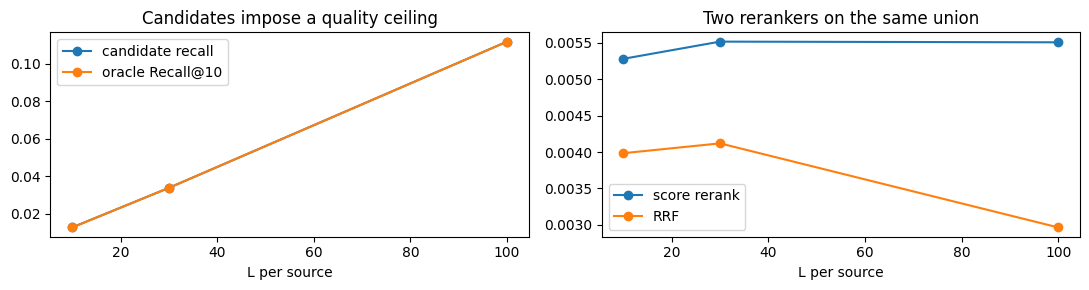

In [46]:
def rerank_union(candidates, scorer, users, k=K):
    result = {}
    for u in users:
        ids = np.unique(np.concatenate([candidates[s][u] for s in CHANNELS]))
        values = scorer(np.array([u]), ids)[0]
        result[u] = topk(values, ids, k)[0]
    return result


L_GRID = [10, 30, 100]
largest_candidates = {s: retrieve(factor_scorer(models[s]), sorted(ground_valid), seen_train,
                                  active_train, k=max(L_GRID)) for s in CHANNELS}
candidate_rows = []
for limit in L_GRID:
    candidates = {s: {u: ids[:limit] for u, ids in rankings.items()} for s, rankings in largest_candidates.items()}
    begin = perf_counter()
    fused = {u: rrf([candidates[s][u] for s in CHANNELS], equal_weights, K) for u in ground_valid}
    reranked = rerank_union(candidates, blend_scorer(models, best_weights, active_train), sorted(ground_valid))
    post_seconds = perf_counter() - begin
    recalls, oracle, union_sizes = [], [], []
    for u, relevant in ground_valid.items():
        union = set().union(*(set(candidates[s][u]) for s in CHANNELS))
        hits = len(union & relevant)
        recalls.append(hits / len(relevant)); oracle.append(min(K, hits) / len(relevant)); union_sizes.append(len(union))
    candidate_rows.append({"L per source": limit, "mean union size": np.mean(union_sizes),
                           "candidate recall": np.mean(recalls), "oracle Recall@10": np.mean(oracle),
                           "RRF NDCG@10": metric_rows(fused, ground_valid).mean()["NDCG@10"],
                           "rerank NDCG@10": metric_rows(reranked, ground_valid).mean()["NDCG@10"],
                           "merge + rerank seconds": post_seconds})
candidate_results = pd.DataFrame(candidate_rows)
display(candidate_results)
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(candidate_results["L per source"], candidate_results["candidate recall"], "o-", label="candidate recall")
axes[0].plot(candidate_results["L per source"], candidate_results["oracle Recall@10"], "o-", label="oracle Recall@10")
axes[1].plot(candidate_results["L per source"], candidate_results["rerank NDCG@10"], "o-", label="score rerank")
axes[1].plot(candidate_results["L per source"], candidate_results["RRF NDCG@10"], "o-", label="RRF")
for ax in axes: ax.legend(); ax.set_xlabel("L per source")
axes[0].set_title("Candidates impose a quality ceiling"); axes[1].set_title("Two rerankers on the same union")
plt.tight_layout(); plt.show()


The candidate table separates the achievable recall ceiling from ordering
within the union. High candidate recall alone does not imply high NDCG@10.
The reported merge-and-rerank time excludes candidate generation, which was
performed once at the largest L.

### Experiment 16. Retrieval block size

$$M_{\mathrm{scores}}=B_uB_i\cdot\mathrm{sizeof(dtype)}.$$

Exact retrieval should return the same top-K for different item-block sizes.
Use up to 100 validation users for this latency microbenchmark; quality
comparisons still use the full fixed evaluation cohort. Python sorting also
contributes overhead in this reference implementation.


In [47]:
latency_users = sorted(ground_valid)[:min(100, len(ground_valid))]
retrieval_rows, exact_reference = [], None
for block in [256, 2048, 8192]:
    begin = perf_counter()
    ranked = retrieve(blend_scorer(models, best_weights, active_train), latency_users,
                       seen_train, active_train, user_block=32, item_block=block)
    seconds = perf_counter() - begin
    if exact_reference is None:
        exact_reference = ranked
    for u in latency_users:
        np.testing.assert_array_equal(ranked[u], exact_reference[u])
    retrieval_rows.append({"item block": block, "users": len(latency_users), "seconds": seconds,
                           "one float64 score block MiB": 32 * min(block, seen_train.shape[1]) * 8 / 2**20})
display(pd.DataFrame(retrieval_rows))


,item block,users,seconds,one float64 score block MiB
0,256,100,0.276013,0.0625
1,2048,100,0.212857,0.5000
2,8192,100,0.207150,2.0000


### Experiment 17. Compress item factors to int8

For each item vector:

$$s_i=\max_j|y_{ij}|/127,\quad q_{ij}=\mathrm{round}(y_{ij}/s_i),\quad
\hat f(u,i)=s_i\,x_u^\top q_i.$$

Store int8 codes and one float32 scale per item; keep user queries in float32.
Without clipping, rounding gives
$|x_u^\top(y_i-s_iq_i)|\le\frac{s_i}{2}\|x_u\|_1$.
Small score errors can reorder nearby candidates, so measure top-K overlap
and NDCG as well as storage. This NumPy implementation dequantizes for scoring;
it does not imply a speedup without a specialized int8 kernel.


In [48]:
def quantize_rows(vectors):
    maximum = np.max(np.abs(vectors), axis=1)
    scale = np.where(maximum > 0, maximum / 127., 1.).astype(np.float32)
    codes = np.rint(vectors / scale[:, None]).clip(-127, 127).astype(np.int8)
    return codes, scale


def dequantized_scores(queries, codes, scale):
    return (queries @ codes.astype(np.float32).T) * scale[None, :]


quantized_items, quantized_scales = quantize_rows(models["early"].item_factors)
quantized_rankings = retrieve(
    lambda users, ids: dequantized_scores(models["early"].user_factors[users], quantized_items[ids], quantized_scales[ids]),
    sorted(ground_valid), seen_train, active_train)
overlap = np.mean([len(set(quantized_rankings[u]) & set(valid_rankings["early"][u])) / K for u in ground_valid])
display(pd.DataFrame([
    {"storage": "float32 item factors", "MiB": models["early"].item_factors.nbytes / 2**20,
     "NDCG@10": valid_metrics["early"]["NDCG@10"]},
    {"storage": "int8 + per-row scale", "MiB": (quantized_items.nbytes + quantized_scales.nbytes) / 2**20,
     "NDCG@10": metric_rows(quantized_rankings, ground_valid).mean()["NDCG@10"]},
]))
print("Mean top-10 overlap:", overlap)


,storage,MiB,NDCG@10
0,float32 item factors,1.724854,0.002452
1,int8 + per-row scale,0.467148,0.002601


Mean top-10 overlap: 0.9885269121813031


### Sharing user factors across signals

Independent ALS models do not share representations. An alternative uses one
user factor $x_u$ and separate item factors $y_i^{(s)}$:

$$L=\sum_s\eta_s\sum_{u,i}c_{ui}^{(s)}(p_{ui}^{(s)}-x_u^\top y_i^{(s)})^2
 +\lambda_X\|X\|_F^2+\sum_s\lambda_s\|Y^{(s)}\|_F^2.$$

With item factors fixed, the user update is

$$\left[\sum_s\eta_sY_s^\top C_u^{(s)}Y_s+\lambda_X I\right]x_u
 =\sum_s\eta_sY_s^\top C_u^{(s)}p_u^{(s)}.$$

Apply the Gram decomposition to each channel. Add user regularization
$\lambda_X$ once. The item update for channel $s$ is

$$[\eta_sX^\top C_i^{(s)}X+\lambda_s I]y_i^{(s)}
 =\eta_sX^\top C_i^{(s)}p_i^{(s)}.$$

This changes representation learning, unlike late fusion of independent
models. Sharing may help rare actions, but conflicting signals can also hurt.
Weights $\eta_s$ balance objectives with different density and confidence scales.

### References

- Hu, Koren, Volinsky (2008), *Collaborative Filtering for Implicit Feedback
  Datasets*: [DOI](https://doi.org/10.1109/ICDM.2008.22).
- Takács, Pilászy, Tikk (2011), *Applications of the Conjugate Gradient Method
  for Implicit Feedback Collaborative Filtering*: [DOI](https://doi.org/10.1145/2043932.2043987).
- Cormack, Clarke, Buettcher (2009), *Reciprocal Rank Fusion outperforms
  Condorcet and individual Rank Learning Methods*: [DOI](https://doi.org/10.1145/1571941.1572114).
- [VK-LSVD dataset description](https://huggingface.co/datasets/deepvk/VK-LSVD/blob/084a18386e149a454dd6dbe0123478e75c6b09ce/README.md).
- [`implicit` CPU ALS implementation](https://github.com/benfred/implicit/blob/v0.7.3/implicit/cpu/als.py),
  [API reference](https://benfred.github.io/implicit/api/models/cpu/als.html).


### Experiment 18. Shared-user ALS for watch and actions

Use a bounded reference problem with up to 500 active training users and
1500 popular training items. Shared and independent models see the same
restricted data. The main comparisons above continue to use the full snapshot.

The shared user step sums channel normal systems and adds $\lambda_X$ once.
Each item step is ordinary iALS with regularization $\lambda_s/\eta_s$.


In [49]:
def shared_user_step(confidences, item_factors, weights, reg, batch_size=32):
    d = item_factors[0].shape[1]
    base = sum(w * Y.T @ Y for w, Y in zip(weights, item_factors)) + reg * np.eye(d)
    result = np.empty((confidences[0].shape[0], d))
    for begin in range(0, len(result), batch_size):
        end = min(begin + batch_size, len(result))
        A = np.broadcast_to(base, (end - begin, d, d)).copy()
        b = np.zeros((end - begin, d))
        for offset, u in enumerate(range(begin, end)):
            for C, Y, weight in zip(confidences, item_factors, weights):
                left, right = C.indptr[u:u + 2]
                local = Y[C.indices[left:right]]
                values = C.data[left:right]
                c = np.abs(values)
                A[offset] += weight * local.T @ ((c - 1)[:, None] * local)
                b[offset] += weight * local.T @ np.where(values > 0, c, 0.)
        result[begin:end] = np.linalg.solve(A, b[..., None])[..., 0]
    return result


Reference shape: (500, 1500) shared objective: [np.float64(164333.76452033548), np.float64(113093.86729155012), np.float64(109723.82329351603), np.float64(108668.71639947442), np.float64(108205.59887149368), np.float64(107940.58510026477), np.float64(107756.12074081374), np.float64(107614.11016637653)]


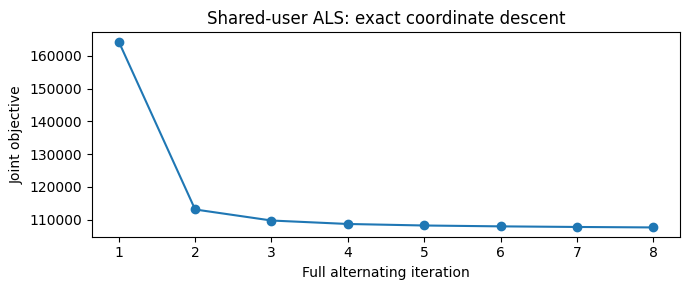

In [50]:
reference_users = np.argsort(-np.diff(seen_train.indptr), kind="stable")[:min(500, seen_train.shape[0])]
reference_items = np.argsort(-np.asarray(seen_train.sum(axis=0)).ravel(), kind="stable")[:min(1500, seen_train.shape[1])]
reference_Cs = [C_train[s][reference_users][:, reference_items].astype(float).tocsr() for s in ["watch", "actions"]]
eta = [.5, .5]
rng = np.random.default_rng(SEED)
shared_Y = [rng.normal(0, .01, (len(reference_items), 16)) for _ in reference_Cs]
shared_X = rng.normal(0, .01, (len(reference_users), 16))
shared_trace = []
for iteration in range(8):
    shared_X = shared_user_step(reference_Cs, shared_Y, eta, REG)
    shared_Y = [update_rows(C.T.tocsr(), shared_X, REG / weight, batch_size=32)
                for C, weight in zip(reference_Cs, eta)]
    loss = sum(weight * als_loss(C, shared_X, Y, 0.) for C, Y, weight in zip(reference_Cs, shared_Y, eta))
    loss += REG * ((shared_X**2).sum() + sum((Y**2).sum() for Y in shared_Y))
    shared_trace.append(loss)
assert np.all(np.diff(shared_trace) < 1e-6)
print("Reference shape:", reference_Cs[0].shape, "shared objective:", shared_trace)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(np.arange(1, 9), shared_trace, "o-")
ax.set(xlabel="Full alternating iteration", ylabel="Joint objective", title="Shared-user ALS: exact coordinate descent")
plt.tight_layout(); plt.show()


Evaluate whether the shared user vector transfers information from dense
views to sparse actions. Both models rank the same restricted catalog and
use its future action targets. Their absolute NDCG is not directly comparable
with the full-catalog experiments.

A restricted historical catalog can retain very few future positives. Read
the retained user count before interpreting the comparison; a tiny cohort
checks the implementation but cannot establish better generalization.


In [51]:
independent_actions, _, _ = fit_model(reference_Cs[1].astype(np.float32), factors=16, iterations=8, use_cg=False, reg=REG / eta[1])
user_to_local = {int(u): j for j, u in enumerate(reference_users)}
item_to_local = {int(i): j for j, i in enumerate(reference_items)}
local_ground = {user_to_local[u]: {item_to_local[i] for i in rel if i in item_to_local}
                for u, rel in ground_valid.items() if u in user_to_local}
local_ground = {u: rel for u, rel in local_ground.items() if rel}
local_seen = seen_train[reference_users][:, reference_items].tocsr()
local_active = np.asarray(local_seen.sum(axis=0)).ravel() > 0
if local_ground:
    shared_rank = retrieve(lambda users, items: shared_X[users] @ shared_Y[1][items].T,
                            sorted(local_ground), local_seen, local_active)
    independent_rank = retrieve(factor_scorer(independent_actions), sorted(local_ground), local_seen, local_active)
    display(pd.DataFrame({"independent actions": metric_rows(independent_rank, local_ground).mean(),
                          "shared user / actions head": metric_rows(shared_rank, local_ground).mean()}).T)
    print("Reference validation users:", len(local_ground))
else:
    print("No future positive targets in the bounded reference catalog; joint-loss verification remains valid.")


,Recall@10,NDCG@10,Dislike@10
independent actions,0.0,0.0,0.0
shared user / actions head,0.0,0.0,0.0


Reference validation users: 5


The shared model optimizes a joint loss and transfers information through
$X$. Its value for actions is determined by future ranking quality, not by
decreasing joint loss alone. Late fusion instead leaves learned representations
independent and combines their predictions.


### Freeze configurations before testing

Select the confidence transformation, history policy and negative-feedback
policy by validation NDCG within their predefined families. The wide early
model has dimension 144. Freeze these choices and the mixture weights before
computing any test metrics.


In [52]:
lab_results = pd.DataFrame(lab_rows)
selected_lab_names = []
for family in ["confidence", "history", "negative"]:
    subset = lab_results[lab_results.family == family]
    selected_lab_names.append(subset.loc[subset["NDCG@10"].idxmax(), "experiment"])
selected_lab_names.append("early / equal total dimension")
display(lab_results[lab_results.experiment.isin(selected_lab_names)])
print("Frozen before test:", selected_lab_names, "z weights:", best_weights)


,experiment,family,fit seconds,retrieval seconds,Recall@10,NDCG@10,Dislike@10
1,linear seconds,confidence,91.158526,1.045477,0.007900,0.007462,0.000212
14,last 2 weeks,history,30.877680,1.002494,0.007464,0.006151,0.000000
25,dislike + weak skips,negative,99.223903,1.050357,0.004201,0.003645,0.000000
26,early / equal total dimension,capacity,128.002925,1.149199,0.001758,0.001710,0.000000


Frozen before test: ['linear seconds', 'last 2 weeks', 'dislike + weak skips', 'early / equal total dimension'] z weights: (0.25, 0.5, 0.25)


## 9. Refit and evaluate on the future test week

Add validation feedback to the history and train on weeks 0–8. Extend ID
mappings without changing existing rows. Keep epochs, signal transformations
and selected hyperparameters fixed. The seen-filter now includes validation
impressions. Test feedback contributes to none of the training signals,
popularity estimates or normalization moments.

Evaluate the predefined model families. A paired user bootstrap compares
z-score fusion with early fusion on the same test users. The interval describes
variation across this cohort, not across future calendar periods or random
seeds, and does not estimate causal online lift.


,test coverage
all positive pairs,30312.000000
warm-ID positive pairs,19378.000000
warm-ID coverage,0.639285
cohort warm positive pairs,5774.000000
eligible cohort pairs,5774.000000
after-filter coverage in cohort,1.000000
eligible users,1343.000000
cohort users,3000.000000


,Recall@10,NDCG@10,Dislike@10,eligible users
watch,0.003007,0.002500,0.000000,1343
like,0.006470,0.005577,0.000149,1343
actions,0.003296,0.002144,0.000074,1343
early,0.002581,0.002208,0.000000,1343
popularity,0.000750,0.000901,0.000074,1343
raw equal blend,0.004524,0.004333,0.000000,1343
z blend / selected,0.008551,0.006575,0.000074,1343
RRF / equal,0.004956,0.003471,0.000074,1343


z blend − early, mean ΔNDCG@10: 0.004366344939660833 paired bootstrap 95% interval: [0.00140048 0.00711672]
Test candidate union recall: 0.05427846674110713
Secondary completed-watch target, users: 2996 {'Recall@10': 0.0027554343052733888, 'NDCG@10': 0.010939396598108652, 'Dislike@10': 3.3377837116154874e-05}


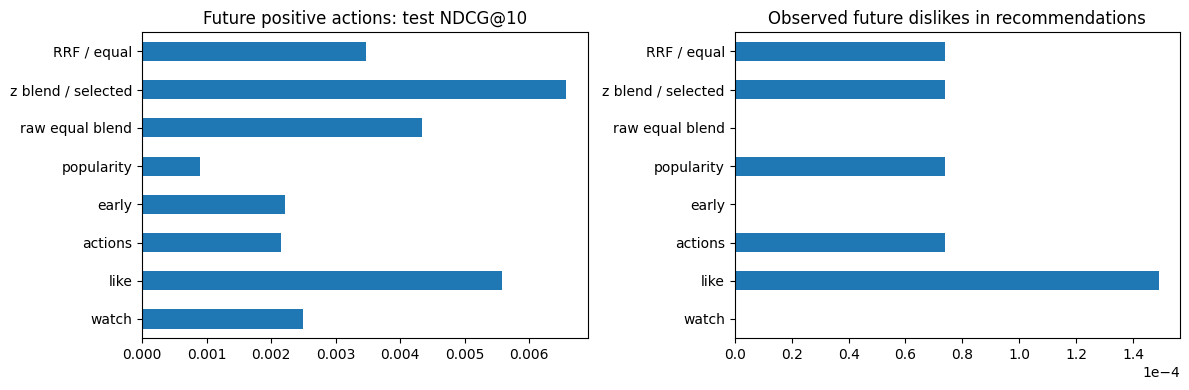

In [53]:
final_registry = copy.deepcopy(registry)
final_registry.extend(weeks[VALID_WEEK])
if SYNTHETIC:
    final_meta = item_meta
else:
    final_ids = pl.Series("item_id", list(final_registry.items), dtype=pl.UInt32)
    final_meta = (pl.scan_parquet(DATA_DIR / "metadata/items_metadata.parquet")
                  .select("item_id", "duration")
                  .filter(pl.col("item_id").is_in(final_ids.implode()))
                  .collect(engine="streaming"))
final_events = pl.concat([weeks[w] for w in [*TRAIN_WEEKS, VALID_WEEK]])
final_events = final_events.join(final_meta, on="item_id", how="left").with_columns(
    pl.when(pl.col("duration").fill_null(0) > 0)
      .then((pl.col("timespent").cast(pl.Float64) / pl.col("duration")).clip(0, 2))
      .otherwise(0.).alias("watch_ratio")
)
C_final, seen_final = matrices(final_events, final_registry)
active_final = np.asarray(seen_final.sum(axis=0)).ravel() > 0
final_models, final_fit_times = {}, {}
for s in [*CHANNELS, "early"]:
    final_models[s], final_fit_times[s], _ = fit_model(C_final[s])

# First and only test evaluation stage. Keep the same preselected training-user cohort.
ground_test, bad_test, long_test, test_audit = future_targets(
    weeks[TEST_WEEK], final_registry, seen_final, eval_cohort, final_meta)
assert ground_test, "No eligible test users; change the protocol before drawing conclusions"
display(pd.Series(test_audit, name="test coverage"))
test_rankings = {s: retrieve(factor_scorer(m), sorted(ground_test), seen_final, active_final)
                 for s, m in final_models.items()}
popular_final = np.asarray(seen_final.sum(axis=0)).ravel().astype(float)
test_rankings["popularity"] = retrieve(
    lambda users, ids: np.broadcast_to(popular_final[ids], (len(users), len(ids))),
    sorted(ground_test), seen_final, active_final)
for name, weights, normalize in [("raw equal blend", equal_weights, False),
                                  ("z blend / selected", best_weights, True)]:
    test_rankings[name] = retrieve(blend_scorer(final_models, weights, active_final, normalize),
                                   sorted(ground_test), seen_final, active_final)
test_candidates = {s: retrieve(factor_scorer(final_models[s]), sorted(ground_test), seen_final,
                               active_final, k=CANDIDATES) for s in CHANNELS}
test_rankings["RRF / equal"] = {
    u: rrf([test_candidates[s][u] for s in CHANNELS], equal_weights, K) for u in ground_test
}
per_user_test = {name: metric_rows(ranking, ground_test, bad_test) for name, ranking in test_rankings.items()}
test_results = pd.DataFrame({name: rows.mean() for name, rows in per_user_test.items()}).T
test_results["eligible users"] = len(ground_test)
display(test_results.round(6))

delta = (per_user_test["z blend / selected"]["NDCG@10"] - per_user_test["early"]["NDCG@10"]).to_numpy()
rng = np.random.default_rng(SEED)
boot = np.array([rng.choice(delta, len(delta), replace=True).mean() for _ in range(2000)])
print("z blend − early, mean ΔNDCG@10:", delta.mean(),
      "paired bootstrap 95% interval:", np.quantile(boot, [.025, .975]))

test_union_recall = np.mean([
    len(set().union(*(set(test_candidates[s][u]) for s in CHANNELS)) & ground_test[u]) / len(ground_test[u])
    for u in ground_test])
print("Test candidate union recall:", test_union_recall)

# Secondary target on its own eligible group; report users so it cannot be confused with primary NDCG.
if long_test:
    long_rankings = retrieve(blend_scorer(final_models, best_weights, active_final),
                             sorted(long_test), seen_final, active_final)
    print("Secondary completed-watch target, users:", len(long_test),
          metric_rows(long_rankings, long_test, bad_test).mean().to_dict())
plot_results = test_results.round(6)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_results["NDCG@10"].plot.barh(ax=axes[0], title="Future positive actions: test NDCG@10")
plot_results["Dislike@10"].plot.barh(ax=axes[1], title="Observed future dislikes in recommendations")
axes[1].ticklabel_format(axis="x", style="sci", scilimits=(0, 0), useOffset=False)
if not test_results["Dislike@10"].any():
    axes[1].set_xlim(0, .01)
    axes[1].text(.5, .5, "No observed dislike hits\nin this test cohort", ha="center", va="center",
                 transform=axes[1].transAxes)
plt.tight_layout()
plt.show()


### Experiment 19. Test the validation-selected policies

Refit one validation-selected configuration from each confidence, history and
negative-feedback family on train plus validation. Evaluate them on the same
test users as the primary models. Include wide early fusion as an equal-capacity
control; do not select new weights from the test table.


In [54]:
for name in selected_lab_names:
    spec = lab_specs[name]
    final_C_variant = matrix_from_events(final_events, final_registry, **spec["matrix"])
    fitted, seconds, _ = fit_model(final_C_variant, **spec["fit"])
    key = "validation selected: " + name
    final_models[key] = fitted
    test_rankings[key] = retrieve(factor_scorer(fitted), sorted(ground_test), seen_final, active_final)
    per_user_test[key] = metric_rows(test_rankings[key], ground_test, bad_test)
final_action_counts = np.asarray((C_final["actions"] > 0).sum(axis=1)).ravel()
test_rankings["z blend / action gate"] = retrieve(
    gated_scorer(final_models, best_weights, active_final, final_action_counts),
    sorted(ground_test), seen_final, active_final)
per_user_test["z blend / action gate"] = metric_rows(test_rankings["z blend / action gate"], ground_test, bad_test)
test_results = pd.DataFrame({name: frame.mean() for name, frame in per_user_test.items()}).T
test_results["users"] = len(ground_test)
display(test_results.round(6))
print("Frozen family configurations:", selected_lab_names)


,Recall@10,NDCG@10,Dislike@10,users
watch,0.003007,0.002500,0.000000,1343
like,0.006470,0.005577,0.000149,1343
actions,0.003296,0.002144,0.000074,1343
early,0.002581,0.002208,0.000000,1343
popularity,0.000750,0.000901,0.000074,1343
raw equal blend,0.004524,0.004333,0.000000,1343
z blend / selected,0.008551,0.006575,0.000074,1343
RRF / equal,0.004956,0.003471,0.000074,1343
validation selected: linear seconds,0.009429,0.007394,0.000000,1343
validation selected: last 2 weeks,0.007192,0.006296,0.000074,1343


Frozen family configurations: ['linear seconds', 'last 2 weeks', 'dislike + weak skips', 'early / equal total dimension']


### Experiment 20. Users with and without historical actions

An average can hide opposite effects across user groups. Define groups using
past share/bookmark activity only. For a segment $S$:

$$\Delta_S=|S|^{-1}\sum_{u\in S}
(\mathrm{NDCG}_{u,blend}-\mathrm{NDCG}_{u,early}).$$

Also report catalog coverage and the mean training popularity of recommended
items. These describe model behavior; they are not additional test-based
selection criteria.


In [55]:
segment_rows, catalog_rows = [], []
for name in ["popularity", "early", "actions", "z blend / selected", "z blend / action gate", "RRF / equal"]:
    frame = per_user_test[name]
    for label, mask in [("no historical actions", final_action_counts[frame.index.to_numpy()] == 0),
                         ("has historical actions", final_action_counts[frame.index.to_numpy()] > 0)]:
        if mask.any():
            segment_rows.append({"model": name, "segment": label, "users": int(mask.sum()),
                                 "NDCG@10": frame.loc[mask, "NDCG@10"].mean()})
    recommended = np.concatenate(list(test_rankings[name].values()))
    catalog_rows.append({"model": name, "catalog coverage": np.unique(recommended).size / active_final.sum(),
                         "mean log training popularity": np.log1p(popular_final[recommended]).mean()})
segment_results, catalog_results = pd.DataFrame(segment_rows), pd.DataFrame(catalog_rows)
display(segment_results.pivot(index="model", columns="segment", values="NDCG@10"))
display(catalog_results.set_index("model"))


segment,has historical actions,no historical actions
model,,
RRF / equal,0.003048,0.004671
actions,0.002900,0.000000
early,0.001268,0.004877
popularity,0.000939,0.000793
z blend / action gate,0.006386,0.007111
z blend / selected,0.006386,0.007111


,catalog coverage,mean log training popularity
model,,
popularity,0.014657,8.917435
early,0.280237,8.033559
actions,0.091536,7.103253
z blend / selected,0.203844,7.801520
z blend / action gate,0.203844,7.801520
RRF / equal,0.224325,7.569031


### Experiment 21. Inspect recommendations and channel contributions

Show ten recommendations for two eligible users selected by past activity,
with watch, like and actions contributions and observed future feedback.
Their selection does not depend on whether the ranking contains a hit.

Video IDs are anonymous; titles and descriptions are unavailable. A score
decomposition explains the model's ranking, not the user's causal preference.


In [56]:
ordered_test_users = sorted(ground_test, key=lambda u: (final_action_counts[u], u))
example_users = list(dict.fromkeys([ordered_test_users[0], ordered_test_users[-1]]))
reverse_items = {idx: raw for raw, idx in final_registry.items.items()}
final_stats = {s: normalization_stats(final_models[s], active_final) for s in CHANNELS}
for u in example_users:
    records = []
    for position, i in enumerate(test_rankings["z blend / selected"][u], 1):
        record = {"rank": position, "raw item ID": reverse_items[int(i)],
                  "future positive action": i in ground_test[u],
                  "future observed dislike": i in bad_test.get(u, ()),
                  "training shows": int(popular_final[i])}
        for signal, weight in zip(CHANNELS, best_weights):
            mean, inverse = final_stats[signal]
            score = final_models[signal].user_factors[u] @ final_models[signal].item_factors[i]
            record[signal + " contribution"] = weight * (score - mean[u]) * inverse[u]
        records.append(record)
    print("User index:", u, "historical action pairs:", final_action_counts[u])
    display(pd.DataFrame(records))


User index: 12 historical action pairs: 0


,rank,raw item ID,future positive action,future observed dislike,training shows,watch contribution,like contribution,actions contribution
0,1,168348413,False,False,3662,0.188231,4.372517,0.0
1,2,271168082,False,False,4771,0.232266,3.453362,0.0
2,3,163064586,False,False,4220,0.453957,2.731927,0.0
3,4,267676161,False,False,3705,0.272258,2.667041,0.0
4,5,600412448,False,False,4977,0.394403,2.476808,0.0
5,6,59713718,False,False,1445,0.127714,2.692784,0.0
6,7,61739504,False,False,4549,0.496658,2.302600,0.0
7,8,581444947,False,False,3817,0.201354,2.573490,0.0
8,9,230917580,False,False,4209,0.354317,2.350445,0.0
9,10,423256053,False,False,6120,0.494967,2.204246,0.0


User index: 9027 historical action pairs: 102


,rank,raw item ID,future positive action,future observed dislike,training shows,watch contribution,like contribution,actions contribution
0,1,17258097,False,False,1675,0.799339,5.106522,-0.349423
1,2,25830888,False,False,1333,0.602089,4.143188,-0.060533
2,3,417856939,False,False,5950,0.452651,4.309414,-0.149082
3,4,437608706,False,False,3075,0.315645,3.563633,0.114509
4,5,352064132,False,False,6191,0.463703,2.956249,0.392266
5,6,514291106,False,False,6789,0.656906,3.209613,-0.157713
6,7,524727603,False,False,6042,0.369887,3.089077,0.224209
7,8,560675242,False,False,810,0.256797,3.473052,-0.060533
8,9,493626073,False,False,3648,0.418570,2.328663,0.800629
9,10,179324802,False,False,142,0.291181,3.316605,-0.060533


### Results of the applied comparisons


In [57]:
best_conf = confidence_results.loc[confidence_results["NDCG@10"].idxmax()]
best_history = history_results.loc[history_results["NDCG@10"].idxmax()]
fastest_solver = solver_results.loc[solver_results["fit seconds"].idxmin()]
print(f"Confidence: validation-best = {best_conf['experiment']}, NDCG={best_conf['NDCG@10']:.5f}.")
print(f"History: validation-best = {best_history['experiment']}, NDCG={best_history['NDCG@10']:.5f}.")
print(f"Solver: fastest measured = {fastest_solver['solver']}, {fastest_solver['fit seconds']:.2f}s, "
      f"NDCG={fastest_solver['NDCG@10']:.5f}.")
print("Candidate union recall by L:", list(zip(candidate_results['L per source'],
                                              candidate_results['candidate recall'].round(4))))
print(f"Quantized item-factor storage: {(quantized_items.nbytes + quantized_scales.nbytes) / 2**20:.2f} MiB; "
      f"top-10 overlap={overlap:.1%}.")
print("Separate architectures have explicit equal-capacity controls; global and activity-aware mixtures "
      "are reported on the same test cohort.")


Confidence: validation-best = linear seconds, NDCG=0.00746.
History: validation-best = last 2 weeks, NDCG=0.00615.
Solver: fastest measured = CG q=2, 19.38s, NDCG=0.00243.
Candidate union recall by L: [(10, 0.0127), (30, 0.0338), (100, 0.1118)]
Quantized item-factor storage: 0.47 MiB; top-10 overlap=98.9%.
Separate architectures have explicit equal-capacity controls; global and activity-aware mixtures are reported on the same test cohort.


## 10. Conclusions


In [58]:
last = weekly_results[weekly_results["train through"] == TRAIN_WEEKS[-1]].set_index("mode")
warm_quality = last.loc["warm / 3", "NDCG@10"]
random_quality = last.loc["random / 3", "NDCG@10"]
print(f"1. Final training snapshot: warm / 3 NDCG={warm_quality:.5f}; random / 3={random_quality:.5f}; "
      f"random / {ITERATIONS}={last.loc['random / full', 'NDCG@10']:.5f}.")
if warm_quality > random_quality:
    print("   Previous factors improve the three-epoch starting point on this snapshot.")
else:
    print("   Warm initialization does not improve next-week NDCG at three epochs on this snapshot.")
timing = weekly_results[weekly_results["train through"] < TRAIN_WEEKS[-1]].groupby("mode")["update seconds"].sum()
print(f"2. Cumulative fit time before the last snapshot, excluding loss tracing: warm / 3={timing['warm / 3']:.2f}s; "
      f"random / 3={timing['random / 3']:.2f}s; random / {ITERATIONS}={timing['random / full']:.2f}s.")
print(f"3. Test NDCG: early={test_results.loc['early', 'NDCG@10']:.5f}; "
      f"raw blend={test_results.loc['raw equal blend', 'NDCG@10']:.5f}; "
      f"z blend={test_results.loc['z blend / selected', 'NDCG@10']:.5f}; "
      f"RRF={test_results.loc['RRF / equal', 'NDCG@10']:.5f}; "
      f"popularity={test_results.loc['popularity', 'NDCG@10']:.5f}.")
lower, upper = np.quantile(boot, [.025, .975])
direction = "positive" if lower > 0 else "negative" if upper < 0 else "consistent with zero"
print(f"4. z blend minus early: {delta.mean():+.5f}; 95% paired interval [{lower:+.5f}, {upper:+.5f}]. "
      f"The difference is {direction} on this test split.")
print(f"5. Test cohort: {len(ground_test)} users; warm-ID coverage="
      f"{test_audit['warm-ID coverage']:.1%}; candidate union recall={test_union_recall:.1%}.")
if not test_results["Dislike@10"].any():
    print("6. All models have zero observed future-dislike hits in the top ten. With this rare signal and cohort, "
          "Dislike@10 cannot distinguish the models or establish the absence of unwanted recommendations.")


1. Final training snapshot: warm / 3 NDCG=0.00267; random / 3=0.00285; random / 20=0.00245.
   Warm initialization does not improve next-week NDCG at three epochs on this snapshot.
2. Cumulative fit time before the last snapshot, excluding loss tracing: warm / 3=41.52s; random / 3=41.24s; random / 20=268.51s.
3. Test NDCG: early=0.00221; raw blend=0.00433; z blend=0.00657; RRF=0.00347; popularity=0.00090.
4. z blend minus early: +0.00437; 95% paired interval [+0.00140, +0.00712]. The difference is positive on this test split.
5. Test cohort: 1343 users; warm-ID coverage=63.9%; candidate union recall=5.4%.


### What the comparisons establish

- Shared Gram matrices and sparse corrections make iALS feasible without
  enumerating all pairs. Row blocks control temporary memory while preserving
  an exact half-step. Dimension affects both storage and the quadratic or cubic
  cost of solving normal systems.
- Warm starts reuse learned factors. Their benefit depends on convergence and
  the cost of previous updates. Fold-in requires complete current user history
  and consistent item factors; it does not replace joint catalog training.
- Preference defines the target; confidence defines its weight. A strongly
  weighted zero target for a dislike is different from a missing observation.
  Seconds, completion ratios and deliberate actions need distinct interpretations.
- Early fusion, independent models and shared-user ALS combine information at
  different stages. Equal-capacity controls separate representation choices
  from simply adding parameters. Normalized score fusion, activity gates and
  RRF make different trade-offs in scale, coverage and ranking.
- Candidate generation sets a ceiling for reranking. Factor compression must
  be assessed through ranking changes, not storage alone. Segment metrics and
  concrete recommendations complement the cohort average.

The measured results apply to this selected audience, catalog and time split.
Completion and positive-action NDCG evaluate different objectives. Offline
ranking metrics and observed dislikes do not measure causal online lift.
